In [141]:
import os
import pandas as pd
import numpy as np
import pickle # save models as pickle files

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
from xgboost import XGBClassifier
from sklearn.utils import resample
from scipy.stats import norm # useful for calculating the upper and lower bounds

### Develop model to predict Died vs did not die(everyone else)

In [142]:
# set working directory

# Load CSV into a DataFrame
file_path = "/Users/hmutegeki/Documents/CAMONET/DARING/Machine Learning/daring_data_merged.csv"
camData_All_full = pd.read_csv(file_path)
print(camData_All_full.head())

Columns (185,263,277,284,285,333,334,348,350,354,355,363,364,369,370,416,417,420,422,433,438,440,441,443,444,445,452,596,597,598,599,600,602,612,617,618,619,621,622,624,626,631,632,633,679,681,684,687,688,690,693,699,706,708,712,715) have mixed types. Specify dtype option on import or set low_memory=False.


    rec_id date_data_collect name_of_rrh re_admit   age     sex res_district  \
0  ARU-100        2025-07-09        Arua      Yes  36.0  Female         Arua   
1  ARU-101        2025-07-09        Arua       No  57.0  Female         Arua   
2  ARU-102        2025-07-09        Arua       No   8.0  Female         Arua   
3  ARU-103        2025-07-09        Arua       No   1.0    Male       Terego   
4  ARU-104        2025-07-10        Arua      Yes  21.0  Female      Maracha   

  res_subcounty   village occupation  ... Sepsis_Diagnosis BSI_Diagnosis  \
0         Oluko  Awindiri        NaN  ...                0             0   
1         Ocebo    Ombaci    Peasant  ...                1             0   
2         Kenya   Jacinto        NaN  ...                0             0   
3        Uriama      Yoro        NaN  ...                0             1   
4        Ombaci     Kurua     Tailor  ...                0             0   

  Meningitis_Diagnosis Ortho_Diagnosis SSS_Diagnosis RTI_Diagn

In [143]:
res_cols = [col for col in camData_All_full.columns if 'first' or 'sec' or 'third' in col]

def res_checker (row):res_cols = [col for col in camData_All_full.columns if 'first' or 'sec' or 'third' in col]

def res_checker (row):
    for col in res_cols:
        if row[col] == 'any_resistance':
            return 'Yes'
    return 'No'

camData_All_full['any_resistance'] = camData_All_full.apply(res_checker, axis = 1)

In [144]:
camData_All_full = camData_All_full.rename(columns={"cormobid_condition": "any_comorbidity"})

In [145]:


# Remove leading/trailing spaces from column names
camData_All_full.columns = camData_All_full.columns.str.strip()

# Replace common missing-value strings with actual NaN
camData_All_full = camData_All_full.replace(
    ["", " ", "NA", "N/A", "na", "n/a", "NULL", "null", "None"],
    np.nan
)

# Separate numeric and categorical columns
numeric_cols = camData_All_full.select_dtypes(include=["number"]).columns
categorical_cols = camData_All_full.select_dtypes(include=["object", "category"]).columns

# Impute numeric columns with median
for col in numeric_cols:
    camData_All_full[col] = camData_All_full[col].fillna(
        camData_All_full[col].median()
    )

# Impute categorical columns with most frequent value
for col in categorical_cols:
    mode_value = camData_All_full[col].mode()
    
    if len(mode_value) > 0:
        camData_All_full[col] = camData_All_full[col].fillna(mode_value[0])

# Optional check
print(camData_All_full.isna().sum())
print("Total missing values remaining:", camData_All_full.isna().sum().sum())

rec_id                            0
date_data_collect                 0
name_of_rrh                       0
re_admit                          0
age                               0
                                 ..
date_at_discharge                 0
date_referral                     0
data_abstraction_form_complete    0
phase                             0
any_resistance                    0
Length: 860, dtype: int64
Total missing values remaining: 241038


In [146]:
print(camData_All_full.shape)

(1913, 860)


In [147]:
print(camData_All_full.shape)

(1913, 860)


In [148]:
wardSummarry = camData_All_full['ward'].value_counts()
print(wardSummarry)

ward
Surgical                      514
Medical                       506
Paediatric                    335
Gynaecology                   179
Orthopaedic                    96
ICU/HDU                        71
Accident and emergency         61
Maternity/Post-Natal ward      56
NICU Unit                      56
TB ward                        22
Private wing                   15
Maternity/ Post-Natal ward      2
Name: count, dtype: int64


In [149]:
# subset a few observations to use for validation
camonet_valData = camData_All_full.sample(1)

# Remove the sampled rows from the original DataFrame
camData_All = camData_All_full.drop(camonet_valData.index)

In [150]:
print(camonet_valData.shape)


(1, 860)


In [151]:
treatOutcomeVal = camonet_valData['treatment_outcome'].value_counts()
print(treatOutcomeVal)


treatment_outcome
Discharged    1
Name: count, dtype: int64


In [152]:
print(camData_All.shape)
treatOutcome = camData_All['treatment_outcome'].value_counts()
print(treatOutcome)

(1912, 860)
treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [153]:
print(camData_All.columns)

Index(['rec_id', 'date_data_collect', 'name_of_rrh', 're_admit', 'age', 'sex',
       'res_district', 'res_subcounty', 'village', 'occupation',
       ...
       'BSI_Diagnosis', 'Meningitis_Diagnosis', 'Ortho_Diagnosis',
       'SSS_Diagnosis', 'RTI_Diagnosis', 'date_at_discharge', 'date_referral',
       'data_abstraction_form_complete', 'phase', 'any_resistance'],
      dtype='object', length=860)


In [154]:
lines = camData_All.columns
with open("list_data.txt", "w") as file:
    file.writelines(lines)

In [155]:
print(camData_All.dtypes)

rec_id                             object
date_data_collect                  object
name_of_rrh                        object
re_admit                           object
age                               float64
                                   ...   
date_at_discharge                  object
date_referral                      object
data_abstraction_form_complete     object
phase                              object
any_resistance                     object
Length: 860, dtype: object


In [170]:
treatOutcome = camData_All['treatment_outcome'].value_counts()
print(treatOutcome)

treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [171]:
camData_sub = camData_All # reassign but do not subset

In [172]:
camData_sub["sex"].value_counts()

sex
Female    968
Male      944
Name: count, dtype: int64

In [173]:
# Extract specific columns
#camDataSub = camData_sub[["site", "age", "sex", "ward", "any_comorbidity", "any_resistance", "antib_prior_admi", "treatment_outcome"]]
camDataSub = camData_sub[["name_of_rrh", "age", "sex", "ward", "antib_prior_admi","any_comorbidity", "any_resistance","treatment_outcome"]]
print(camDataSub.head(25))
# "site, any_comorbidity, any_resistance , referral", 

   name_of_rrh   age     sex                       ward antib_prior_admi  \
0         Arua  36.0  Female                Gynaecology              Yes   
1         Arua  57.0  Female                Orthopaedic          Unknown   
2         Arua   8.0  Female                Gynaecology               No   
3         Arua   1.0    Male                 Paediatric              Yes   
4         Arua  21.0  Female                Gynaecology               No   
5         Arua   0.0    Male                 Paediatric               No   
6         Arua  24.0  Female                    Medical               No   
7         Arua   9.0    Male                 Paediatric              Yes   
8         Arua   1.0    Male                 Paediatric              Yes   
9         Arua  54.0  Female                   Surgical          Unknown   
10        Arua  80.0  Female                   Surgical          Unknown   
11        Arua  42.0    Male                   Surgical               No   
12        Ar

In [174]:
treatOutcome = camDataSub["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
Discharged                      1453
Died                             190
Recovered with complications     111
Self discharged                  103
Referred                          45
Clinical detorioration            10
Name: count, dtype: int64


In [ ]:
### recode the factors
camDataSub["sex"] = np.where(camDataSub["sex"] == "Female", 1, 0)
camDataSub["any_comorbidity"] = np.where(camDataSub["any_comorbidity"] == "Yes", 1, 0)
camDataSub["any_resistance"] = np.where(camDataSub["any_resistance"] == "Yes", 1, 0)
camDataSub["antib_prior_admi"] = np.where(camDataSub["antib_prior_admi"] == "Yes", 1, 0)
camDataSub["treatment_outcome"] = np.where(camDataSub["treatment_outcome"] == "Died", 1, 0)


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/

In [176]:
print(camDataSub.head(8))

  name_of_rrh   age  sex         ward  antib_prior_admi  any_comorbidity  \
0        Arua  36.0    1  Gynaecology                 1                0   
1        Arua  57.0    1  Orthopaedic                 0                0   
2        Arua   8.0    1  Gynaecology                 0                0   
3        Arua   1.0    0   Paediatric                 1                0   
4        Arua  21.0    1  Gynaecology                 0                0   
5        Arua   0.0    0   Paediatric                 0                0   
6        Arua  24.0    1      Medical                 0                0   
7        Arua   9.0    0   Paediatric                 1                0   

   any_resistance  treatment_outcome  
0               0                  0  
1               0                  0  
2               0                  0  
3               0                  0  
4               0                  0  
5               0                  0  
6               0                  0  
7  

In [177]:
# Define the mapping of values
ward_mapping = {
    "Gynaecology":0,
    "ICU/HDU":1,
    "Accident and emergency":3,
    "Maternity/Post-Natal ward":2,
    "Medical":3,
    "NICU":6,
    "Orthopedic":7,
    "Orthopaedic":7,
    "Pediatric":4,
    "Paediatric":4,
    "Private wing":3,
    "Surgical":5,
    "Urology ward":3,
    "TB ward":3,
    "NICU Unit":6,
    "Maternity/ Post-Natal ward":2
}

# Replace the values in the 'ward' column
camDataSub["ward"] = camDataSub["ward"].replace(ward_mapping)

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [178]:
# Define the mapping of values
site_mapping = {
    "Arua": 0,
    "Gulu": 1,
    "Jinja": 2,
    "Kabale": 3,
    "Lira": 4,
    "Masaka": 5,
    "Mbale": 6,
    "Mbarara": 7,
    "Soroti": 8
}

# Replace the values in the 'site' column
camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].replace(site_mapping)

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [179]:
print(camDataSub.head(10))

   name_of_rrh   age  sex  ward  antib_prior_admi  any_comorbidity  \
0            0  36.0    1     0                 1                0   
1            0  57.0    1     7                 0                0   
2            0   8.0    1     0                 0                0   
3            0   1.0    0     4                 1                0   
4            0  21.0    1     0                 0                0   
5            0   0.0    0     4                 0                0   
6            0  24.0    1     3                 0                0   
7            0   9.0    0     4                 1                0   
8            0   1.0    0     4                 1                0   
9            0  54.0    1     5                 0                0   

   any_resistance  treatment_outcome  
0               0                  0  
1               0                  0  
2               0                  0  
3               0                  0  
4               0                 

In [180]:
print(camDataSub.dtypes)

name_of_rrh            int64
age                  float64
sex                    int64
ward                   int64
antib_prior_admi       int64
any_comorbidity        int64
any_resistance         int64
treatment_outcome      int64
dtype: object


In [181]:
# Convert specific columns to 'category' type
camDataSub["name_of_rrh"] = camDataSub["name_of_rrh"].astype('category')
camDataSub["sex"] = camDataSub["sex"].astype('category')
camDataSub["ward"] = camDataSub["ward"].astype('category')
camDataSub["any_comorbidity"] = camDataSub["any_comorbidity"].astype('category')
camDataSub["any_resistance"] = camDataSub["any_resistance"].astype('category')
camDataSub["antib_prior_admi"] = camDataSub["antib_prior_admi"].astype('category')
camDataSub["treatment_outcome"] = camDataSub["treatment_outcome"].astype('category')


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/

In [182]:
print(camDataSub.dtypes)

name_of_rrh          category
age                   float64
sex                  category
ward                 category
antib_prior_admi     category
any_comorbidity      category
any_resistance       category
treatment_outcome    category
dtype: object


In [183]:
#print(LR_model)
#print(LR_model.get_params())
treatOutcome = camDataSub["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
0    1722
1     190
Name: count, dtype: int64


In [184]:
camDataSub["ward"]

0       0
1       7
2       0
3       4
4       0
       ..
1908    3
1909    3
1910    3
1911    3
1912    3
Name: ward, Length: 1912, dtype: category
Categories (8, int64): [0, 1, 2, 3, 4, 5, 6, 7]

In [101]:
!pip install imbalanced-learn

In [ ]:
#Do the modelling

# Initialize lists to store results
svmAccu, svmAccuLow, svmAccuUpp, svmSens, svmSpec, svmPPV, svmNPV, svmPrec, svmRec, svmF1 = [], [], [], [], [], [], [], [], [], []
rfAccu, rfAccuLow, rfAccuUpp, rfSens, rfSpec, rfPPV, rfNPV, rfPrec, rfRec, rfF1 = [], [], [], [], [], [], [], [], [], []
treeAccu, treeAccuLow, treeAccuUpp, treeSens, treeSpec, treePPV, treeNPV, treePrec, treeRec, treeF1 = [], [], [], [], [], [], [], [], [], []
LRAccu, LRAccuLow, LRAccuUpp, LRSens, LRSpec, LRPPV, LRNPV, LRPrec, LRRec, LRF1 = [], [], [], [], [], [], [], [], [], []
BoostAccu, BoostAccuLow, BoostAccuUpp, BoostSens, BoostSpec, BoostPPV, BoostNPV, BoostPrec, BoostRec, BoostF1 = [], [], [], [], [], [], [], [], [], []
# Assuming camDataUsed is a pandas DataFrame
for i in range(100):
    print(i, "--------------------------------------------------------")
    # Shuffle the data
    camData_shfld = camDataSub.sample(frac=1).reset_index(drop=True)
    
    # Select specific columns
    #camData_shfld = camData_shfld[["treatment_outcome", "site", "age", "sex", "anyComorbidity", "anyResistance", "ward", "antib_prior_admi"]]
    camData_shfld = camData_shfld[["name_of_rrh","treatment_outcome", "age", "sex", "ward", "antib_prior_admi"]]
    # Bootstrap sampling
    camData_shfld = resample(camData_shfld, n_samples=2000, replace=True)
    
    # Split into training and testing data
    X = camData_shfld.drop(columns=["treatment_outcome"])
    y = camData_shfld["treatment_outcome"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(X_train.shape)
    

    train_data = pd.concat([X_train, y_train],axis=1)

    # ======================================
    # SPLIT MAJORITY / MINORITY
    # ======================================

    majority_class = train_data[
        train_data["treatment_outcome"] == 0
    ]

    minority_class = train_data[
        train_data["treatment_outcome"] == 1
    ]

    # ======================================
    # CHECK BOTH CLASSES EXIST
    # ======================================

    if len(majority_class) == 0 or len(minority_class) == 0:
        print(f"Skipping iteration {i}: one class missing")
        continue

    # ======================================
    # DOWNSAMPLE MAJORITY CLASS BY HALF
    # ======================================

    majority_half_size = len(majority_class) // 2

    majority_downsampled = resample(
        majority_class,
        replace=False,
        n_samples=majority_half_size,
        random_state=42
    )

    # ======================================
    # COMBINE BALANCED TRAINING DATA
    # ======================================

    balanced_train_data = pd.concat([
        majority_downsampled,
        minority_class
    ])

    # ======================================
    # SHUFFLE BALANCED TRAINING DATA
    # ======================================

    balanced_train_data = balanced_train_data.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

    # ======================================
    # SPLIT BALANCED TRAINING DATA
    # ======================================

    X_train_balanced = balanced_train_data.drop(columns=["treatment_outcome"])

    y_train_balanced = balanced_train_data["treatment_outcome"]

    
    
    ############# SVM
    svm_model = SVC(kernel="rbf", C=10, gamma=0.1, random_state=42)
    svm_model.fit(X_train_balanced, y_train_balanced)
    svm_preds = svm_model.predict(X_test)
    svm_confM = confusion_matrix(y_test, svm_preds)
    svm_report = classification_report(y_test, svm_preds, output_dict=True)
    
    svmAccu.append(svm_report["accuracy"])
    svmAccuLow.append(svm_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / len(y_test))))    
    svmAccuUpp.append(svm_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / len(y_test))))    
    #svmAccuLow.append(svm_report["accuracy"] - 1.96 * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / np.sqrt(len(y_test)))
    #svmAccuUpp.append(svm_report["accuracy"] + 1.96 * np.sqrt((svm_report["accuracy"] * (1 - svm_report["accuracy"])) / np.sqrt(len(y_test)))
    svmSens.append(svm_report["1"]["recall"])
    svmSpec.append(svm_report["0"]["recall"])
    svmPPV.append(svm_report["1"]["precision"])
    svmNPV.append(svm_report["0"]["precision"])
    svmPrec.append(svm_report["1"]["precision"])
    svmRec.append(svm_report["1"]["recall"])
    svmF1.append(svm_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"svm_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(svm_model, f)

    
    ###### Random Forest
    rf_model = RandomForestClassifier(n_estimators=500, random_state=42) #max_features=2, considers all features
    rf_model.fit(X_train_balanced, y_train_balanced)
    rf_preds = rf_model.predict(X_test)
    rf_confM = confusion_matrix(y_test, rf_preds)
    rf_report = classification_report(y_test, rf_preds, output_dict=True)
    
    rfAccu.append(rf_report["accuracy"])
    rfAccuLow.append(rf_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / len(y_test))))    
    rfAccuUpp.append(rf_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / len(y_test))))    
    #rfAccuLow.append(rf_report["accuracy"] - 1.96 * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / np.sqrt(len(y_test))))
    #rfAccuUpp.append(rf_report["accuracy"] + 1.96 * np.sqrt((rf_report["accuracy"] * (1 - rf_report["accuracy"])) / np.sqrt(len(y_test))))
    rfSens.append(rf_report["1"]["recall"])
    rfSpec.append(rf_report["0"]["recall"])
    rfPPV.append(rf_report["1"]["precision"])
    rfNPV.append(rf_report["0"]["precision"])
    rfPrec.append(rf_report["1"]["precision"])
    rfRec.append(rf_report["1"]["recall"])
    rfF1.append(rf_report["1"]["f1-score"])

    # Save model as pickle
    filename = f"rf_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(rf_model, f)
    
    
    ###### Decision Trees
    tree_model = DecisionTreeClassifier(random_state=42)
    tree_model.fit(X_train_balanced, y_train_balanced)
    tree_preds = tree_model.predict(X_test)
    tree_confM = confusion_matrix(y_test, tree_preds)
    tree_report = classification_report(y_test, tree_preds, output_dict=True)
    
    treeAccu.append(tree_report["accuracy"])
    treeAccuLow.append(tree_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / len(y_test))))    
    treeAccuUpp.append(tree_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / len(y_test))))    
    #treeAccuLow.append(tree_report["accuracy"] - 1.96 * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / np.sqrt(len(y_test))))
    #treeAccuUpp.append(tree_report["accuracy"] + 1.96 * np.sqrt((tree_report["accuracy"] * (1 - tree_report["accuracy"])) / np.sqrt(len(y_test))))
    treeSens.append(tree_report["1"]["recall"])
    treeSpec.append(tree_report["0"]["recall"])
    treePPV.append(tree_report["1"]["precision"])
    treeNPV.append(tree_report["0"]["precision"])
    treePrec.append(tree_report["1"]["precision"])
    treeRec.append(tree_report["1"]["recall"])
    treeF1.append(tree_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"tree_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(tree_model, f)
    
    
    ####### Logistic Regression
    LR_model = LogisticRegression(random_state=42)
    LR_model.fit(X_train_balanced, y_train_balanced)
    LR_preds = LR_model.predict(X_test)
    LR_confM = confusion_matrix(y_test, LR_preds)
    LR_report = classification_report(y_test, LR_preds, output_dict=True)
    
    LRAccu.append(LR_report["accuracy"])
    LRAccuLow.append(LR_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / len(y_test))))    
    LRAccuUpp.append(LR_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / len(y_test))))    
    #LRAccuLow.append(LR_report["accuracy"] - 1.96 * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / np.sqrt(len(y_test))))
    #LRAccuUpp.append(LR_report["accuracy"] + 1.96 * np.sqrt((LR_report["accuracy"] * (1 - LR_report["accuracy"])) / np.sqrt(len(y_test))))
    LRSens.append(LR_report["1"]["recall"])
    LRSpec.append(LR_report["0"]["recall"])
    LRPPV.append(LR_report["1"]["precision"])
    LRNPV.append(LR_report["0"]["precision"])
    LRPrec.append(LR_report["1"]["precision"])
    LRRec.append(LR_report["1"]["recall"])
    LRF1.append(LR_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"LR_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(LR_model, f)
    
    
    ####### XGBoost
    boost_model = XGBClassifier(n_estimators=50, random_state=42, enable_categorical=True)
    boost_model.fit(X_train_balanced, y_train_balanced)
    Boost_preds = boost_model.predict(X_test)
    Boost_confM = confusion_matrix(y_test, Boost_preds)
    Boost_report = classification_report(y_test, Boost_preds, output_dict=True)
    
    BoostAccu.append(Boost_report["accuracy"])
    BoostAccuLow.append(Boost_report["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / len(y_test))))    
    BoostAccuUpp.append(Boost_report["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / len(y_test))))    
    #BoostAccuLow.append(Boost_report["accuracy"] - 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    #BoostAccuUpp.append(Boost_report["accuracy"] + 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    BoostSens.append(Boost_report["1"]["recall"])
    BoostSpec.append(Boost_report["0"]["recall"])
    BoostPPV.append(Boost_report["1"]["precision"])
    BoostNPV.append(Boost_report["0"]["precision"])
    BoostPrec.append(Boost_report["1"]["precision"])
    BoostRec.append(Boost_report["1"]["recall"])
    BoostF1.append(Boost_report["1"]["f1-score"])
    
    # Save model as pickle
    filename = f"boost_model_{i}.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(boost_model, f)

0 --------------------------------------------------------
(1600, 5)


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


1 --------------------------------------------------------
(1600, 5)


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


2 --------------------------------------------------------
(1600, 5)


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


... (964 outputs left out)

497 --------------------------------------------------------
(1600, 5)
498 --------------------------------------------------------
(1600, 5)


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


499 --------------------------------------------------------
(1600, 5)


Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


In [188]:
 print(y_train_balanced.value_counts())

treatment_outcome
0    721
1    157
Name: count, dtype: int64


In [189]:
# Create a dictionary from the lists
data = {
    "svmAccu": svmAccu, "svmAccuLow": svmAccuLow, "svmAccuUpp": svmAccuUpp, "svmSens": svmSens, "svmSpec": svmSpec, "svmPPV": svmPPV, "svmNPV": svmNPV, "svmPrec": svmPrec, "svmRec": svmRec, "svmF1": svmF1,
    "rfAccu": rfAccu, "rfAccuLow": rfAccuLow, "rfAccuUpp": rfAccuUpp, "rfSens": rfSens, "rfSpec": rfSpec, "rfPPV": rfPPV, "rfNPV": rfNPV, "rfPrec": rfPrec, "rfRec": rfRec, "rfF1": rfF1,
    "treeAccu": treeAccu, "treeAccuLow": treeAccuLow, "treeAccuUpp": treeAccuUpp, "treeSens": treeSens, "treeSpec": treeSpec, "treePPV": treePPV, "treeNPV": treeNPV, "treePrec": treePrec, "treeRec": treeRec, "treeF1": treeF1,
    "LRAccu": LRAccu, "LRAccuLow": LRAccuLow, "LRAccuUpp": LRAccuUpp, "LRSens": LRSens, "LRSpec": LRSpec, "LRPPV": LRPPV, "LRNPV": LRNPV, "LRPrec": LRPrec, "LRRec": LRRec, "LRF1": LRF1,
   "BoostAccu": BoostAccu, "BoostAccuLow": BoostAccuLow, "BoostAccuUpp": BoostAccuUpp, "BoostSens": BoostSens, "BoostSpec": BoostSpec, "BoostPPV": BoostPPV, "BoostNPV": BoostNPV, "BoostPrec": BoostPrec, "BoostRec": BoostRec, "BoostF1": BoostF1
}

# Convert the dictionary to a DataFrame
results_df = pd.DataFrame(data)

# Display the first few rows of the DataFrame
print(results_df.head())
results_df.to_csv("camonetRes_diedModels500.csv", index=False)

   svmAccu  svmAccuLow  svmAccuUpp   svmSens   svmSpec    svmPPV    svmNPV  \
0   0.8950    0.864958    0.925042  0.473684  0.939227  0.450000  0.944444   
1   0.8800    0.848154    0.911846  0.500000  0.924581  0.437500  0.940341   
2   0.8775    0.845370    0.909630  0.435897  0.925208  0.386364  0.938202   
3   0.8975    0.867777    0.927223  0.470588  0.937158  0.410256  0.950139   
4   0.8600    0.825996    0.894004  0.500000  0.900000  0.357143  0.941860   

    svmPrec    svmRec     svmF1  ...  BoostAccu  BoostAccuLow  BoostAccuUpp  \
0  0.450000  0.473684  0.461538  ...     0.8975      0.867777      0.927223   
1  0.437500  0.500000  0.466667  ...     0.9025      0.873430      0.931570   
2  0.386364  0.435897  0.409639  ...     0.8850      0.853736      0.916264   
3  0.410256  0.470588  0.438356  ...     0.9150      0.887670      0.942330   
4  0.357143  0.500000  0.416667  ...     0.8925      0.862145      0.922855   

   BoostSens  BoostSpec  BoostPPV  BoostNPV  BoostPrec  

In [190]:
summaryStata = pd.DataFrame(results_df.describe())
summaryStata.to_csv("camonetResPy_died500_SUMMARY.csv", index=True)
summaryStata

,svmAccu,svmAccuLow,svmAccuUpp,svmSens,svmSpec,svmPPV,svmNPV,svmPrec,svmRec,svmF1,...,BoostAccu,BoostAccuLow,BoostAccuUpp,BoostSens,BoostSpec,BoostPPV,BoostNPV,BoostPrec,BoostRec,BoostF1
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,...,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.877190,0.845125,0.909255,0.430975,0.926213,0.395273,0.936754,0.395273,0.430975,0.409108,...,0.896385,0.866640,0.926130,0.507154,0.939163,0.484850,0.945465,0.484850,0.507154,0.492195
std,0.017019,0.018924,0.015114,0.089481,0.017864,0.069071,0.009120,0.069071,0.089481,0.069325,...,0.016672,0.018801,0.014545,0.087550,0.016531,0.078313,0.009108,0.078313,0.087550,0.071112
min,0.815000,0.776948,0.853052,0.171429,0.872576,0.205882,0.909836,0.205882,0.171429,0.189189,...,0.842500,0.806802,0.878198,0.210526,0.883008,0.235294,0.918033,0.235294,0.210526,0.222222
25%,0.867500,0.834275,0.900725,0.368421,0.915329,0.352544,0.930435,0.352544,0.368421,0.363636,...,0.885000,0.853736,0.916264,0.450000,0.927577,0.432279,0.939227,0.432279,0.450000,0.449860
50%,0.877500,0.845370,0.909630,0.431818,0.927374,0.392857,0.936813,0.392857,0.431818,0.414634,...,0.897500,0.867777,0.927223,0.512821,0.939310,0.487492,0.945504,0.487492,0.512821,0.494845
75%,0.887500,0.856534,0.918466,0.487947,0.938719,0.437881,0.942322,0.437881,0.487947,0.455903,...,0.907500,0.879107,0.935893,0.567721,0.950276,0.533333,0.951875,0.533333,0.567721,0.541176
max,0.920000,0.893414,0.946586,0.743590,0.977778,0.636364,0.971347,0.636364,0.743590,0.644444,...,0.942500,0.919686,0.965314,0.761905,0.980663,0.758621,0.970414,0.758621,0.761905,0.691358


## VALIDATING ON CAMONET DATASET

In [211]:
camonet_valData = pd.read_csv("camonet_data.csv")

In [212]:
# Remove leading/trailing spaces from column names
camonet_valData.columns = camonet_valData.columns.str.strip()

# Replace common missing-value strings with actual NaN
camonet_valData = camonet_valData.replace(
    ["", " ", "NA", "N/A", "na", "n/a", "NULL", "null", "None"],
    np.nan
)

# Separate numeric and categorical columns
numeric_cols = camonet_valData.select_dtypes(include=["number"]).columns
categorical_cols = camonet_valData.select_dtypes(include=["object", "category"]).columns

# Impute numeric columns with median
for col in numeric_cols:
    camonet_valData[col] = camonet_valData[col].fillna(
        camonet_valData[col].median()
    )

# Impute categorical columns with most frequent value
for col in categorical_cols:
    mode_value = camonet_valData[col].mode()
    
    if len(mode_value) > 0:
        camonet_valData[col] = camonet_valData[col].fillna(mode_value[0])

# Optional check
print(camonet_valData.isna().sum())
print("Total missing values remaining:", camonet_valData.isna().sum().sum())

sion                     0
age                      0
sex                      0
Infection_Site_1         0
Infection_Site_2         0
Infection_Site_3         0
referral                 0
ward                     0
antib_prior_admi         0
Prio_antib_1             0
Prio_antib_2             0
Prio_antib_3             0
Prio_antib_4             0
sympt_dura               0
hiv_status               0
intubated                0
cormobid_condition       0
antibiotics              0
Prescribed_antib_1       0
Prescribed_antib_2       0
Prescribed_antib_3       0
Prescribed_antib_4       0
Prescribed_antib_5       0
organism_isolated        0
growth1                  0
first_organism           0
sec_organism             0
third_organism           0
Resistance               0
antib_aft_culture        0
Antibioitic_aft_cul_1    0
Antibioitic_aft_cul_2    0
complications            0
treatment_outcome        0
length_hosp_stay         0
dtype: int64
Total missing values remaining: 0


In [213]:
camonet_valData.rename(columns={'sion': 'name_of_rrh'}, inplace=True)
camonet_valData.rename(columns={'cormobid_condition': 'any_comorbidity'}, inplace=True)
camonet_valData.rename(columns={'Resistance': 'any_resistance'}, inplace=True)

In [ ]:
# res_cols = [col for col in camonet_valData.columns if 'first' or 'sec' or 'third' in col]

# def res_checker (row):res_cols = [col for col in camonet_valData.columns if 'first' or 'sec' or 'third' in col]

# def res_checker (row):
#     for col in res_cols:
#         if row[col] == 'Resi':
#             return 'Yes'
#     return 'No'

# camonet_valData['any_resistance'] = camonet_valData.apply(res_checker, axis = 1)

In [214]:
print(camonet_valData.head())
camonet_valData.to_csv("camonet_validationData_died500.csv", index=True)

  name_of_rrh   age     sex Infection_Site_1 Infection_Site_2  \
0        Arua   6.0    Male            Brain         Systemic   
1        Arua  13.0    Male            Lungs         Systemic   
2        Arua  11.0    Male         Systemic         Systemic   
3        Arua  18.0    Male    Surgical_site         Systemic   
4        Arua  17.0  Female    Surgical_site         Systemic   

  Infection_Site_3 referral            ward antib_prior_admi Prio_antib_1  \
0  Cardio_vascular      Yes  Pediatric ward          Unknown  ceftriaxone   
1  Cardio_vascular      Yes    Medical ward          Unknown  ceftriaxone   
2  Cardio_vascular       No  Pediatric ward          Unknown  ceftriaxone   
3  Cardio_vascular      Yes   Surgical ward          Unknown  ceftriaxone   
4  Cardio_vascular      Yes  Maternity ward          Unknown  ceftriaxone   

   ...    first_organism       sec_organism  third_organism any_resistance  \
0  ...  Escherichia coli  Acinetobacter spp  Klebsiella spp         

In [215]:
treatOutcome = camonet_valData["treatment_outcome"].value_counts()
print(treatOutcome)

treatment_outcome
Clinical improvement / Recovering    261
Cured/recovered                      158
Died                                  87
Referred/ self discharged             34
Recovered with complications          32
Lost to follow up                     27
Name: count, dtype: int64


In [216]:
# Extract specific desired columns
#camDataVAL1used = camonet_valData[["site", "age", "sex", "ward", "anyComorbidity", "anyResistance", "antib_prior_admi", "treatment_outcome"]]
camDataVAL1used = camonet_valData[["name_of_rrh", "age", "sex", "ward", "any_comorbidity", "any_resistance", "antib_prior_admi", "treatment_outcome"]]
print(camDataVAL1used.head())
# "referral", 

  name_of_rrh   age     sex            ward any_comorbidity any_resistance  \
0        Arua   6.0    Male  Pediatric ward              No             No   
1        Arua  13.0    Male    Medical ward              No             No   
2        Arua  11.0    Male  Pediatric ward             Yes             No   
3        Arua  18.0    Male   Surgical ward              No            Yes   
4        Arua  17.0  Female  Maternity ward             Yes            Yes   

  antib_prior_admi treatment_outcome  
0          Unknown   Cured/recovered  
1          Unknown   Cured/recovered  
2          Unknown   Cured/recovered  
3          Unknown   Cured/recovered  
4          Unknown   Cured/recovered  


In [217]:
### recode the factors
camDataVAL1used["sex"] = np.where(camDataVAL1used["sex"] == "Female", 1, 0)
#camDataSub["referral"] = np.where(camDataSub["referral"] == "Yes", 1, 0)
camDataVAL1used["any_comorbidity"] = np.where(camDataVAL1used["any_comorbidity"] == "Yes", 1, 0)
camDataVAL1used["any_resistance"] = np.where(camDataVAL1used["any_resistance"] == "Yes", 1, 0)
camDataVAL1used["antib_prior_admi"] = np.where(camDataVAL1used["antib_prior_admi"] == "Yes", 1, 0)
camDataVAL1used["treatment_outcome"] = np.where(camDataVAL1used["treatment_outcome"] == "Died", 1, 0)


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/

In [218]:
print(camDataVAL1used.head())

  name_of_rrh   age  sex            ward  any_comorbidity  any_resistance  \
0        Arua   6.0    0  Pediatric ward                0               0   
1        Arua  13.0    0    Medical ward                0               0   
2        Arua  11.0    0  Pediatric ward                1               0   
3        Arua  18.0    0   Surgical ward                0               1   
4        Arua  17.0    1  Maternity ward                1               1   

   antib_prior_admi  treatment_outcome  
0                 0                  0  
1                 0                  0  
2                 0                  0  
3                 0                  0  
4                 0                  0  


In [219]:
# Define the mapping of values
# ward_mapping = {
#     "Gyecology ward": 0,
#     "HDU": 1,
#     "ICU Unit": 1,
#     "Maternity ward": 2,
#     "Medical ward": 3,
#     "NICU": 1,
#     "Orthopedic ward": 3,
#     "Pediatric ward": 4,
#     "Private wing": 3,
#     "Surgical ward": 5,
#     "Urology ward": 3
# }
ward_mapping = {
    "Gynaecology": 0,
    "Gyecology ward": 0,
    "ICU/HDU": 1,
    "Accident and emergency": 3,
    "Maternity/Post-Natal ward": 2,
    "Medical": 3,
    "NICU": 6,
    "Orthopedic": 7,
    "Orthopaedic":7,
    "Orthopedic ward": 7,
    "Pediatric": 4,
    "Paediatric":4,
    "Pediatric ward":4,
    "Private wing": 3,
    "Surgical": 5,
    "Urology ward": 3,
    "TB ward":3,
    "NICU Unit":6,
    "Maternity/ Post-Natal ward":2,
    "HDU": 1,
    "ICU Unit": 1,
    "Maternity ward": 2,
    "Medical ward": 3,
    "NICU": 6,
    "Orthopedic ward": 7,
    "Pediatric ward": 4,
    "Private wing": 3,
    "Surgical ward": 5,
    "Urology ward": 3
}


# Replace the values in the 'ward' column
camDataVAL1used["ward"] = camDataVAL1used["ward"].replace(ward_mapping)


# Define the mapping of values
site_mapping = {
    "Arua": 0,
    "Gulu": 1,
    "Jinja": 2,
    "Kabale": 3,
    "Lira": 4,
    "Masaka": 5,
    "Mbale": 6,
    "Mbarara": 7,
    "Soroti": 8
}

# Replace the values in the 'site' column
camDataVAL1used["name_of_rrh"] = camDataVAL1used["name_of_rrh"].replace(site_mapping)

print(camDataVAL1used.head())

   name_of_rrh   age  sex  ward  any_comorbidity  any_resistance  \
0            0   6.0    0     4                0               0   
1            0  13.0    0     3                0               0   
2            0  11.0    0     4                1               0   
3            0  18.0    0     5                0               1   
4            0  17.0    1     2                1               1   

   antib_prior_admi  treatment_outcome  
0                 0                  0  
1                 0                  0  
2                 0                  0  
3                 0                  0  
4                 0                  0  


Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_g

In [220]:
# Convert specific columns to 'category' type
camDataVAL1used["name_of_rrh"] = camDataVAL1used["name_of_rrh"].astype('category')
camDataVAL1used["sex"] = camDataVAL1used["sex"].astype('category')
camDataVAL1used["ward"] = camDataVAL1used["ward"].astype('category')
camDataVAL1used["any_comorbidity"] = camDataVAL1used["any_comorbidity"].astype('category')
camDataVAL1used["any_resistance"] = camDataVAL1used["any_resistance"].astype('category')
camDataVAL1used["antib_prior_admi"] = camDataVAL1used["antib_prior_admi"].astype('category')
camDataVAL1used["treatment_outcome"] = camDataVAL1used["treatment_outcome"].astype('category')

print(camDataVAL1used.dtypes)

name_of_rrh          category
age                   float64
sex                  category
ward                 category
any_comorbidity      category
any_resistance       category
antib_prior_admi     category
treatment_outcome    category
dtype: object



A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/

In [221]:
# Split into training and testing data
Xval = camDataVAL1used.drop(columns=["treatment_outcome"])
Yval = camDataVAL1used["treatment_outcome"]
print(Xval.head())

  name_of_rrh   age sex ward any_comorbidity any_resistance antib_prior_admi
0           0   6.0   0    4               0              0                0
1           0  13.0   0    3               0              0                0
2           0  11.0   0    4               1              0                0
3           0  18.0   0    5               0              1                0
4           0  17.0   1    2               1              1                0


In [227]:
# match features as they were used in the model, for Xval
#Xval = Xval[["site", "age", "sex", "anyComorbidity", "anyResistance", "ward", "antib_prior_admi"]]
# Xval = Xval[["name_of_rrh","age", "sex", "ward", "antib_prior_admi", "any_comorbidity", "any_resistance"]]
Xval = Xval[["name_of_rrh", "age", "sex", "ward", "antib_prior_admi","any_comorbidity", "any_resistance"]]
print(Xval.head())

  name_of_rrh   age sex ward antib_prior_admi any_comorbidity any_resistance
0           0   6.0   0    4                0               0              0
1           0  13.0   0    3                0               0              0
2           0  11.0   0    4                0               1              0
3           0  18.0   0    5                0               0              1
4           0  17.0   1    2                0               1              1


In [ ]:
# validate all models in folder, and output their results
import os
import pickle

# Define the folder path
folder_path = "/Users/hmutegeki/Documents/CAMONET/DARING/Machine Learning/v4/"  # path to files

# Initialize an empty list to store file names
pickle_files = []
valAccu = []
valAccuLow = []
valAccuUpp = []
valPrec = []
valRec = []
valF1 = []
# Loop through all files in the folder
for file in os.listdir(folder_path):
    print(file, "-------------------------------------------------------------------")
    if file.endswith(".pkl"):  # Check if the file is a pickle file
        pickle_files.append(file)  # Add the file name to the list

    # Load the model
    with open(file, 'rb') as file:
        model = pickle.load(file)
        
    # Make a prediction
    valprediction = model.predict(Xval)
    valConfM = confusion_matrix(Yval, valprediction)
    valReport = classification_report(Yval, valprediction, output_dict=True)

    valAccu.append(valReport["accuracy"])
    valAccuLow.append(valReport["accuracy"] - (norm.ppf((1 + 0.95) / 2) * np.sqrt((valReport["accuracy"] * (1 - valReport["accuracy"])) / len(Yval))))    
    valAccuUpp.append(valReport["accuracy"] + (norm.ppf((1 + 0.95) / 2) * np.sqrt((valReport["accuracy"] * (1 - valReport["accuracy"])) / len(Yval))))    
    BoostAccuLow.append(Boost_report["accuracy"] - 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    BoostAccuUpp.append(Boost_report["accuracy"] + 1.96 * np.sqrt((Boost_report["accuracy"] * (1 - Boost_report["accuracy"])) / np.sqrt(len(y_test))))
    BoostSens.append(Boost_report["1"]["recall"])
    BoostSpec.append(Boost_report["0"]["recall"])
    BoostPPV.append(Boost_report["1"]["precision"])
    BoostNPV.append(Boost_report["0"]["precision"])
    valPrec.append(valReport["1"]["precision"])
    valRec.append(valReport["1"]["recall"])
    valF1.append(valReport["1"]["f1-score"])
    # Output the list of pickle file names
    print("Pickle files found:", pickle_files)


svm_model_359.pkl -------------------------------------------------------------------


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- any_comorbidity
- any_resistance


In [ ]:
# Create a dictionary from the lists
#valData = {"Model": pickle_files, "Validation Accuracy": valAccu, "Accu_upp": valAccuUpp, "Accu_lwr": valAccuLow, "val_precision": valPrec, 
#    "val_recall": valRec, "val_F1": valF1}

valData = {"Model": pickle_files, "Validation Accuracy": valAccu, "valAccu_lwr": valAccuLow, "valAccu_upp": valAccuUpp}

print(valData)
# Convert the dictionary to a DataFrame
valResults_df = pd.DataFrame(valData)

# Display the first few rows of the DataFrame
print(valResults_df.head())
valResults_df.to_csv("camonetValidation_resDied500Models.csv", index=False)

{'Model': ['tree_model_147.pkl', 'LR_model_42.pkl', 'tree_model_1.pkl', 'tree_model_153.pkl', 'svm_model_359.pkl', 'svm_model_371.pkl', 'svm_model_417.pkl', 'LR_model_253.pkl', 'LR_model_247.pkl', 'svm_model_403.pkl', 'svm_model_365.pkl', 'rf_model_220.pkl', 'LR_model_95.pkl', 'tree_model_184.pkl', 'LR_model_81.pkl', 'tree_model_190.pkl', 'rf_model_234.pkl', 'LR_model_290.pkl', 'tree_model_20.pkl', 'tree_model_34.pkl', 'LR_model_284.pkl', 'rf_model_208.pkl', 'tree_model_345.pkl', 'tree_model_423.pkl', 'tree_model_437.pkl', 'tree_model_351.pkl', 'tree_model_379.pkl', 'svm_model_173.pkl', 'svm_model_167.pkl', 'tree_model_386.pkl', 'svm_model_198.pkl', 'tree_model_392.pkl', 'tree_model_231.pkl', 'LR_model_119.pkl', 'rf_model_89.pkl', 'LR_model_2.pkl', 'rf_model_195.pkl', 'rf_model_181.pkl', 'svm_model_79.pkl', 'tree_model_225.pkl', 'LR_model_125.pkl', 'svm_model_51.pkl', 'tree_model_219.pkl', 'svm_model_45.pkl', 'LR_model_131.pkl', 'rf_model_156.pkl', 'rf_model_142.pkl', 'svm_model_92.pkl

## Explainability

In [104]:
!pip install lime shap

In [106]:
import lime
import lime.lime_tabular
import shap
import matplotlib.pyplot as plt
import numpy as np

X does not have valid feature names, but LogisticRegression was fitted with feature names
X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names


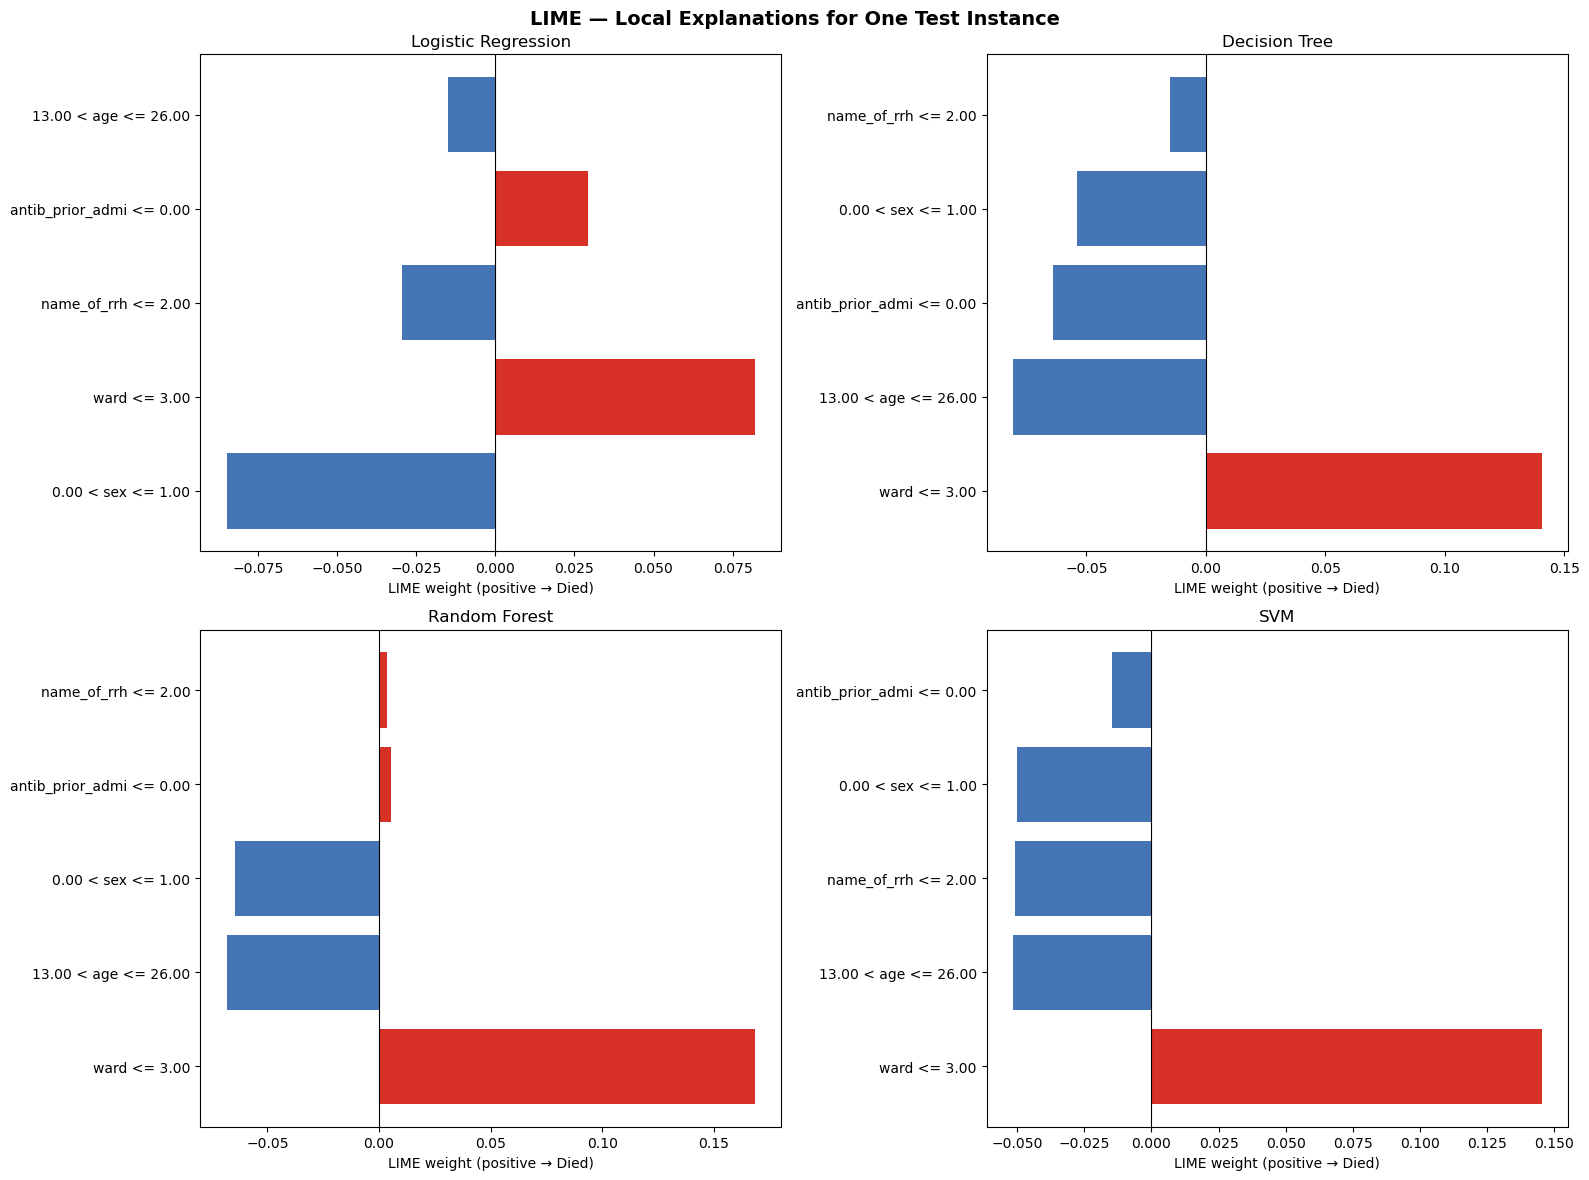

True label for this instance: 0


The figure layout has changed to tight
The figure layout has changed to tight


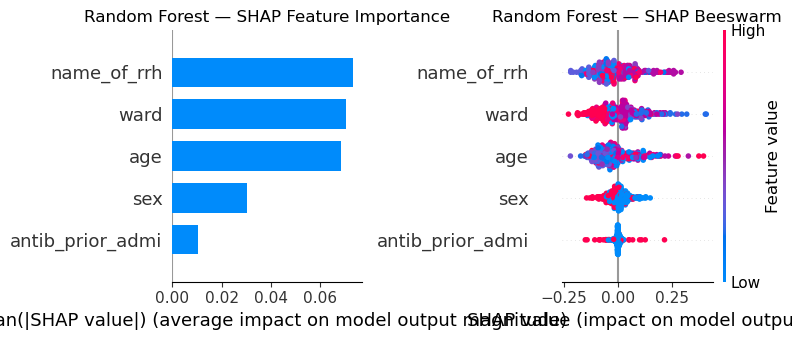

The figure layout has changed to tight


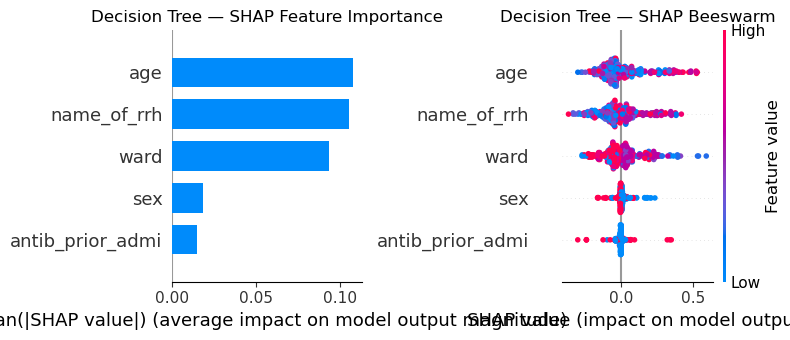

The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)
The figure layout has changed to tight


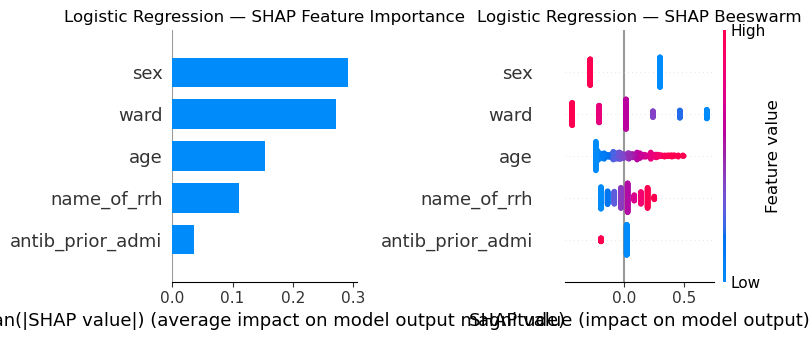

Computing SHAP for SVM (KernelExplainer) — this may take a moment...


X does not have valid feature names, but SVC was fitted with feature names


  0%|          | 0/50 [00:00<?, ?it/s]

X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid fea

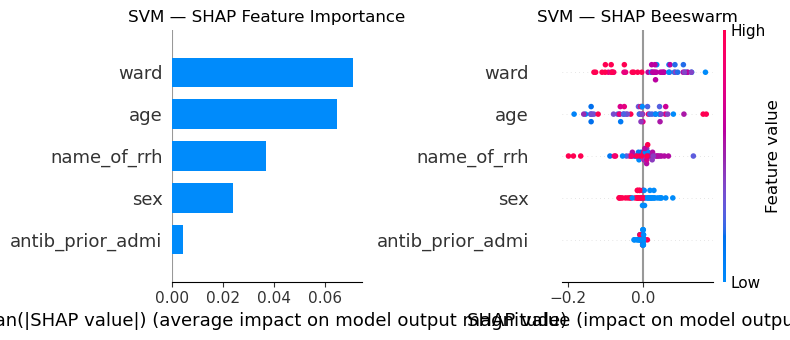

Explainability plots saved: lime_explanations.png, shap_rf.png, shap_tree.png, shap_lr.png, shap_svm.png


In [ ]:
# ============================================================
# EXPLAINABILITY — LIME and SHAP on test data
# Uses X_test, y_test, X_train_balanced from last training fold
# ============================================================

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]
class_names = ["Survived (0)", "Died (1)"]

# Convert to numpy for LIME/SHAP compatibility
X_test_np = X_test.values
X_train_np = X_train_balanced.values

# ----------------------------------------------------------
# LIME — Local explanations for one test instance per model
# ----------------------------------------------------------
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Pick one test instance (first sample)
lime_instance = X_test_np[0]

models_lime = {
    "Logistic Regression": LR_model,
    "Decision Tree":       tree_model,
    "Random Forest":       rf_model,
    "SVM":                 svm_model,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("LIME — Local Explanations for One Test Instance", fontsize=14, fontweight="bold")

for ax, (name, model) in zip(axes.flat, models_lime.items()):
    if hasattr(model, "predict_proba"):
        predict_fn = model.predict_proba
    else:
        # SVM fallback: wrap decision_function into probabilities via sigmoid
        def predict_fn(X, m=model):
            scores = m.decision_function(X)
            proba = 1 / (1 + np.exp(-scores))
            return np.column_stack([1 - proba, proba])
    exp = lime_explainer.explain_instance(
        lime_instance,
        predict_fn,
        num_features=len(feature_names),
        labels=(1,)
    )
    vals  = [v for _, v in exp.as_list(label=1)]
    feats = [f for f, _ in exp.as_list(label=1)]
    colors = ["#d73027" if v > 0 else "#4575b4" for v in vals]
    ax.barh(feats, vals, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("LIME weight (positive → Died)")

plt.tight_layout()
plt.savefig("lime_explanations.png", dpi=150, bbox_inches="tight")
plt.show()
print("True label for this instance:", y_test.values[0])

# --- -------------------------------------------------------
# SHAP — Global feature importance across test set
# ----------------------------------------------------------

# --- Random Forest (TreeExplainer) ---
rf_shap = shap.TreeExplainer(rf_model)
rf_shap_vals = rf_shap.shap_values(X_test_np)   # shape: [n_classes, n_samples, n_features]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plt.sca(axes[0])
shap.summary_plot(
    rf_shap_vals[1] if isinstance(rf_shap_vals, list) else rf_shap_vals,
    X_test_np, feature_names=feature_names,
    plot_type="bar", show=False
)
axes[0].set_title("Random Forest — SHAP Feature Importance")

plt.sca(axes[1])
shap.summary_plot(
    rf_shap_vals[1] if isinstance(rf_shap_vals, list) else rf_shap_vals,
    X_test_np, feature_names=feature_names,
    show=False
)
axes[1].set_title("Random Forest — SHAP Beeswarm")
plt.tight_layout()
plt.savefig("shap_rf.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Decision Tree (TreeExplainer) ---
tree_shap = shap.TreeExplainer(tree_model)
tree_shap_vals = tree_shap.shap_values(X_test_np)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plt.sca(axes[0])
shap.summary_plot(
    tree_shap_vals[1] if isinstance(tree_shap_vals, list) else tree_shap_vals,
    X_test_np, feature_names=feature_names,
    plot_type="bar", show=False
)
axes[0].set_title("Decision Tree — SHAP Feature Importance")

plt.sca(axes[1])
shap.summary_plot(
    tree_shap_vals[1] if isinstance(tree_shap_vals, list) else tree_shap_vals,
    X_test_np, feature_names=feature_names,
    show=False
)
axes[1].set_title("Decision Tree — SHAP Beeswarm")
plt.tight_layout()
plt.savefig("shap_tree.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Logistic Regression (LinearExplainer) ---
lr_shap = shap.LinearExplainer(LR_model, X_train_np, feature_perturbation="interventional")
lr_shap_vals = lr_shap.shap_values(X_test_np)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plt.sca(axes[0])
shap.summary_plot(lr_shap_vals, X_test_np, feature_names=feature_names, plot_type="bar", show=False)
axes[0].set_title("Logistic Regression — SHAP Feature Importance")

plt.sca(axes[1])
shap.summary_plot(lr_shap_vals, X_test_np, feature_names=feature_names, show=False)
axes[1].set_title("Logistic Regression — SHAP Beeswarm")
plt.tight_layout()
plt.savefig("shap_lr.png", dpi=150, bbox_inches="tight")
plt.show()

# --- SVM (KernelExplainer — uses a small background sample for speed) ---
print("Computing SHAP for SVM (KernelExplainer) — this may take a moment...")
background = shap.sample(X_train_np, 50, random_state=42)  # small background for speed

def svm_predict_proba(X):
    scores = svm_model.decision_function(X)
    proba  = 1 / (1 + np.exp(-scores))
    return np.column_stack([1 - proba, proba])

svm_shap = shap.KernelExplainer(svm_predict_proba, background)
svm_shap_vals = svm_shap.shap_values(X_test_np[:50], nsamples=100)  # limit to 50 test rows

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plt.sca(axes[0])
shap.summary_plot(
    svm_shap_vals[1] if isinstance(svm_shap_vals, list) else svm_shap_vals,
    X_test_np[:50], feature_names=feature_names,
    plot_type="bar", show=False
)
axes[0].set_title("SVM — SHAP Feature Importance")

plt.sca(axes[1])
shap.summary_plot(
    svm_shap_vals[1] if isinstance(svm_shap_vals, list) else svm_shap_vals,
    X_test_np[:50], feature_names=feature_names,
    show=False
)
axes[1].set_title("SVM — SHAP Beeswarm")
plt.tight_layout()
plt.savefig("shap_svm.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explainability plots saved: lime_explanations.png, shap_rf.png, shap_tree.png, shap_lr.png, shap_svm.png")


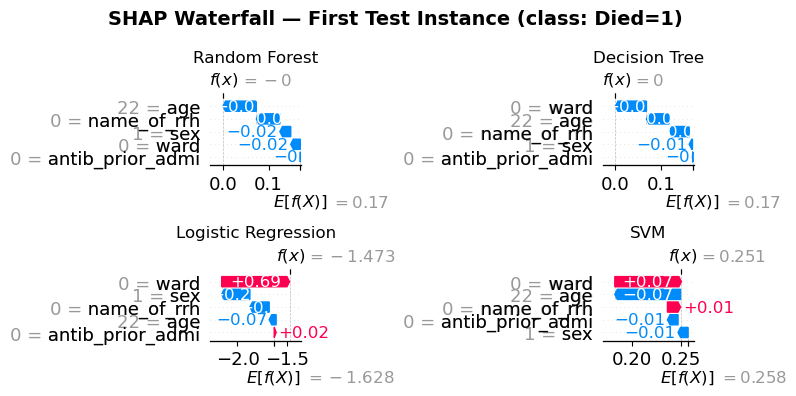

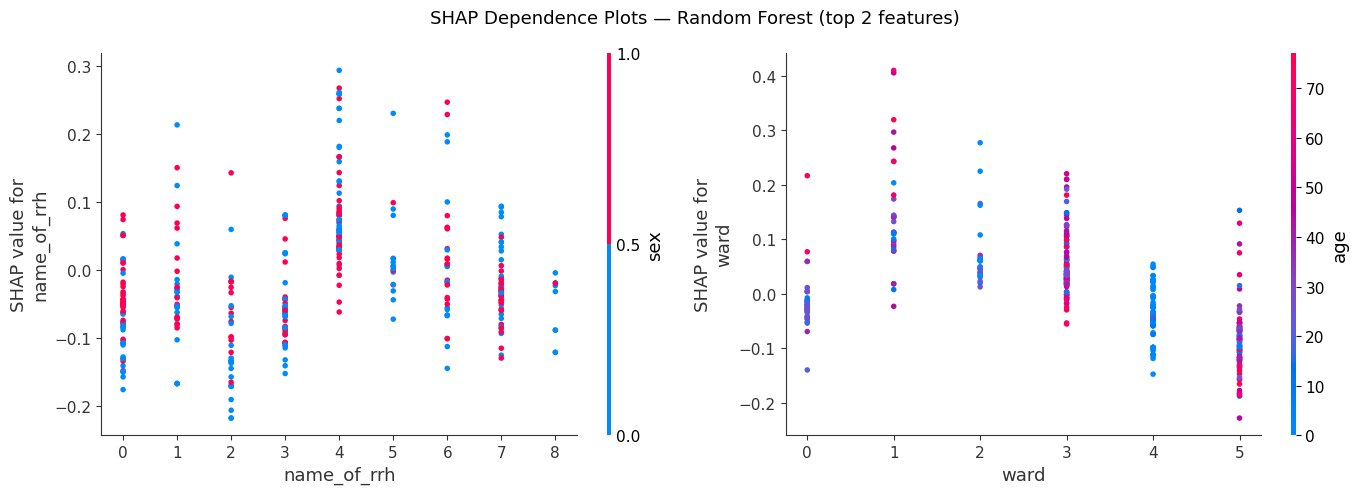

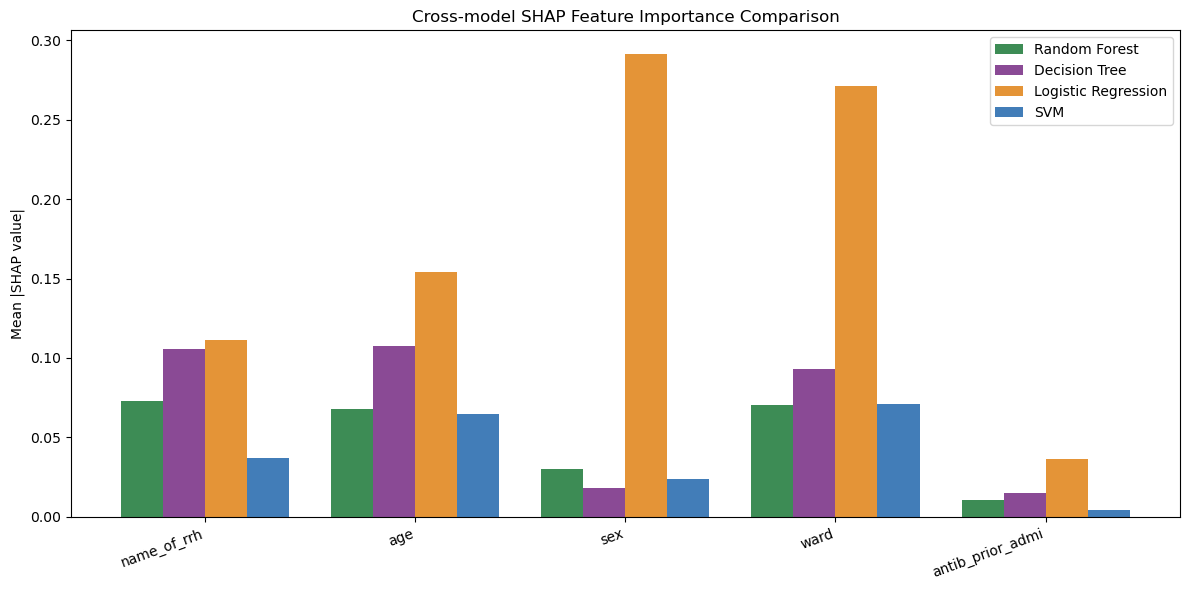

                  Random Forest  Decision Tree  Logistic Regression     SVM
name_of_rrh              0.0730         0.1055               0.1113  0.0369
age                      0.0682         0.1073               0.1544  0.0646
sex                      0.0301         0.0183               0.2916  0.0237
ward                     0.0702         0.0933               0.2713  0.0708
antib_prior_admi         0.0104         0.0148               0.0364  0.0041


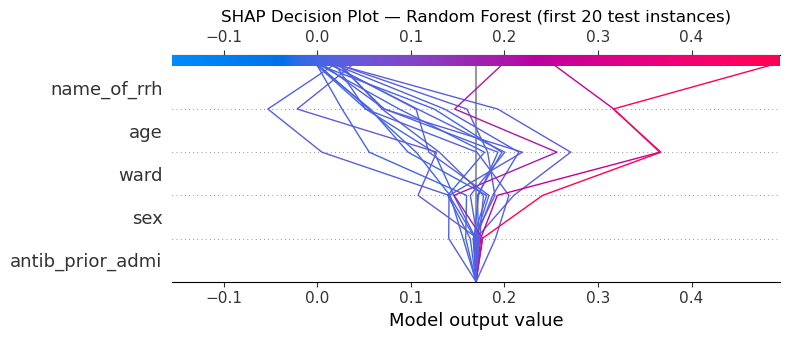

RF force plot (first 10 instances) saved → shap_force_rf_top10.html


The figure layout has changed to tight


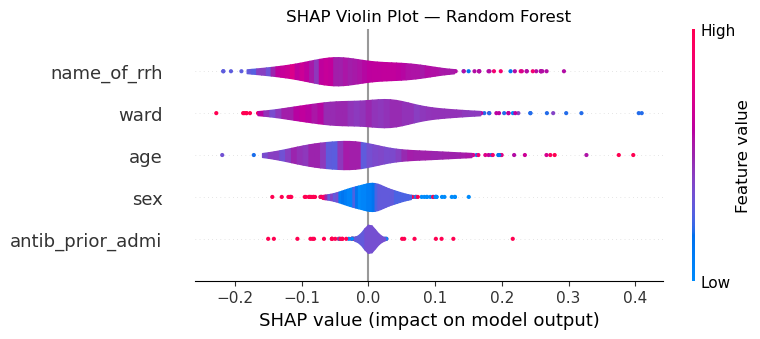

Saved: shap_waterfall.png | shap_dependence_rf.png | shap_cross_model_comparison.png
shap_decision_rf.png | shap_force_rf_top10.html | shap_violin_rf.png


In [109]:
# ============================================================
# SHAP — Extended Visualisations
# Waterfall | Dependence | Decision | Force | Cross-model bar
# Requires the previous SHAP cell to have been run first
# ============================================================
import pandas as pd

# Helper: pull class-1 SHAP values + expected value regardless of explainer type
def get_shap1(shap_vals, explainer):
    if isinstance(shap_vals, list):
        sv = shap_vals[1]
        ev = explainer.expected_value[1] if hasattr(explainer.expected_value, "__len__") else explainer.expected_value
    else:
        sv = shap_vals
        ev = explainer.expected_value if not hasattr(explainer.expected_value, "__len__") else float(np.array(explainer.expected_value).flat[-1])
    return sv, float(ev)


# ----------------------------------------------------------
# 1. Waterfall plots — first test instance, all 4 models
# ----------------------------------------------------------
model_shap_info = {
    "Random Forest":       (rf_shap_vals,   rf_shap,   X_test_np),
    "Decision Tree":       (tree_shap_vals, tree_shap, X_test_np),
    "Logistic Regression": (lr_shap_vals,   lr_shap,   X_test_np),
    "SVM":                 (svm_shap_vals,  svm_shap,  X_test_np[:50]),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle("SHAP Waterfall — First Test Instance (class: Died=1)", fontsize=14, fontweight="bold")

for ax, (name, (sv_raw, expl, X_sub)) in zip(axes.flat, model_shap_info.items()):
    sv, ev = get_shap1(sv_raw, expl)
    shap_exp = shap.Explanation(
        values=sv[0],
        base_values=ev,
        data=X_sub[0],
        feature_names=feature_names
    )
    plt.sca(ax)
    shap.plots.waterfall(shap_exp, show=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()


# ----------------------------------------------------------
# 2. Dependence plots — top 2 RF features coloured by interaction
# ----------------------------------------------------------
rf_sv1, _ = get_shap1(rf_shap_vals, rf_shap)
top2_idx = np.argsort(np.abs(rf_sv1).mean(axis=0))[::-1][:2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("SHAP Dependence Plots — Random Forest (top 2 features)", fontsize=13)
for ax, feat_idx in zip(axes, top2_idx):
    plt.sca(ax)
    shap.dependence_plot(
        feat_idx, rf_sv1, X_test_np,
        feature_names=feature_names,
        ax=ax, show=False
    )
plt.tight_layout()
plt.savefig("shap_dependence_rf.png", dpi=150, bbox_inches="tight")
plt.show()


# ----------------------------------------------------------
# 3. Cross-model mean |SHAP| comparison — grouped bar chart
# ----------------------------------------------------------
rf_sv1,   _  = get_shap1(rf_shap_vals,   rf_shap)
tree_sv1, _  = get_shap1(tree_shap_vals, tree_shap)
lr_sv1,   _  = get_shap1(lr_shap_vals,   lr_shap)
svm_sv1,  _  = get_shap1(svm_shap_vals,  svm_shap)

mean_abs = {
    "Random Forest":       np.abs(rf_sv1).mean(axis=0),
    "Decision Tree":       np.abs(tree_sv1).mean(axis=0),
    "Logistic Regression": np.abs(lr_sv1).mean(axis=0),
    "SVM":                 np.abs(svm_sv1).mean(axis=0),
}
comparison_df = pd.DataFrame(mean_abs, index=feature_names)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(feature_names))
width = 0.2
palette = ["#1b7837", "#762a83", "#e08214", "#2166ac"]
for i, (model_name, color) in enumerate(zip(mean_abs.keys(), palette)):
    ax.bar(x + i * width, comparison_df[model_name], width, label=model_name, color=color, alpha=0.85)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(feature_names, rotation=20, ha="right")
ax.set_ylabel("Mean |SHAP value|")
ax.set_title("Cross-model SHAP Feature Importance Comparison")
ax.legend()
plt.tight_layout()
plt.savefig("shap_cross_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print(comparison_df.round(4).to_string())


# ----------------------------------------------------------
# 4. Decision plot — RF, first 20 test instances
# ----------------------------------------------------------
rf_sv1_full, rf_ev = get_shap1(rf_shap_vals, rf_shap)
fig, ax = plt.subplots(figsize=(10, 8))
plt.sca(ax)
shap.decision_plot(
    rf_ev, rf_sv1_full[:20],
    feature_names=feature_names,
    show=False
)
ax.set_title("SHAP Decision Plot — Random Forest (first 20 test instances)")
plt.tight_layout()
plt.savefig("shap_decision_rf.png", dpi=150, bbox_inches="tight")
plt.show()


# ----------------------------------------------------------
# 5. Force plot — RF, first 10 test instances (HTML)
# ----------------------------------------------------------
force_plot = shap.force_plot(
    rf_ev,
    rf_sv1_full[:10],
    X_test_np[:10],
    feature_names=feature_names,
    matplotlib=False
)
shap.save_html("shap_force_rf_top10.html", force_plot)
print("RF force plot (first 10 instances) saved → shap_force_rf_top10.html")


# ----------------------------------------------------------
# 6. Violin / SHAP value distribution per feature — RF
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
plt.sca(ax)
shap.summary_plot(
    rf_sv1_full, X_test_np,
    feature_names=feature_names,
    plot_type="violin",
    show=False
)
ax.set_title("SHAP Violin Plot — Random Forest")
plt.tight_layout()
plt.savefig("shap_violin_rf.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved: shap_waterfall.png | shap_dependence_rf.png | shap_cross_model_comparison.png")
print("shap_decision_rf.png | shap_force_rf_top10.html | shap_violin_rf.png")


X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names


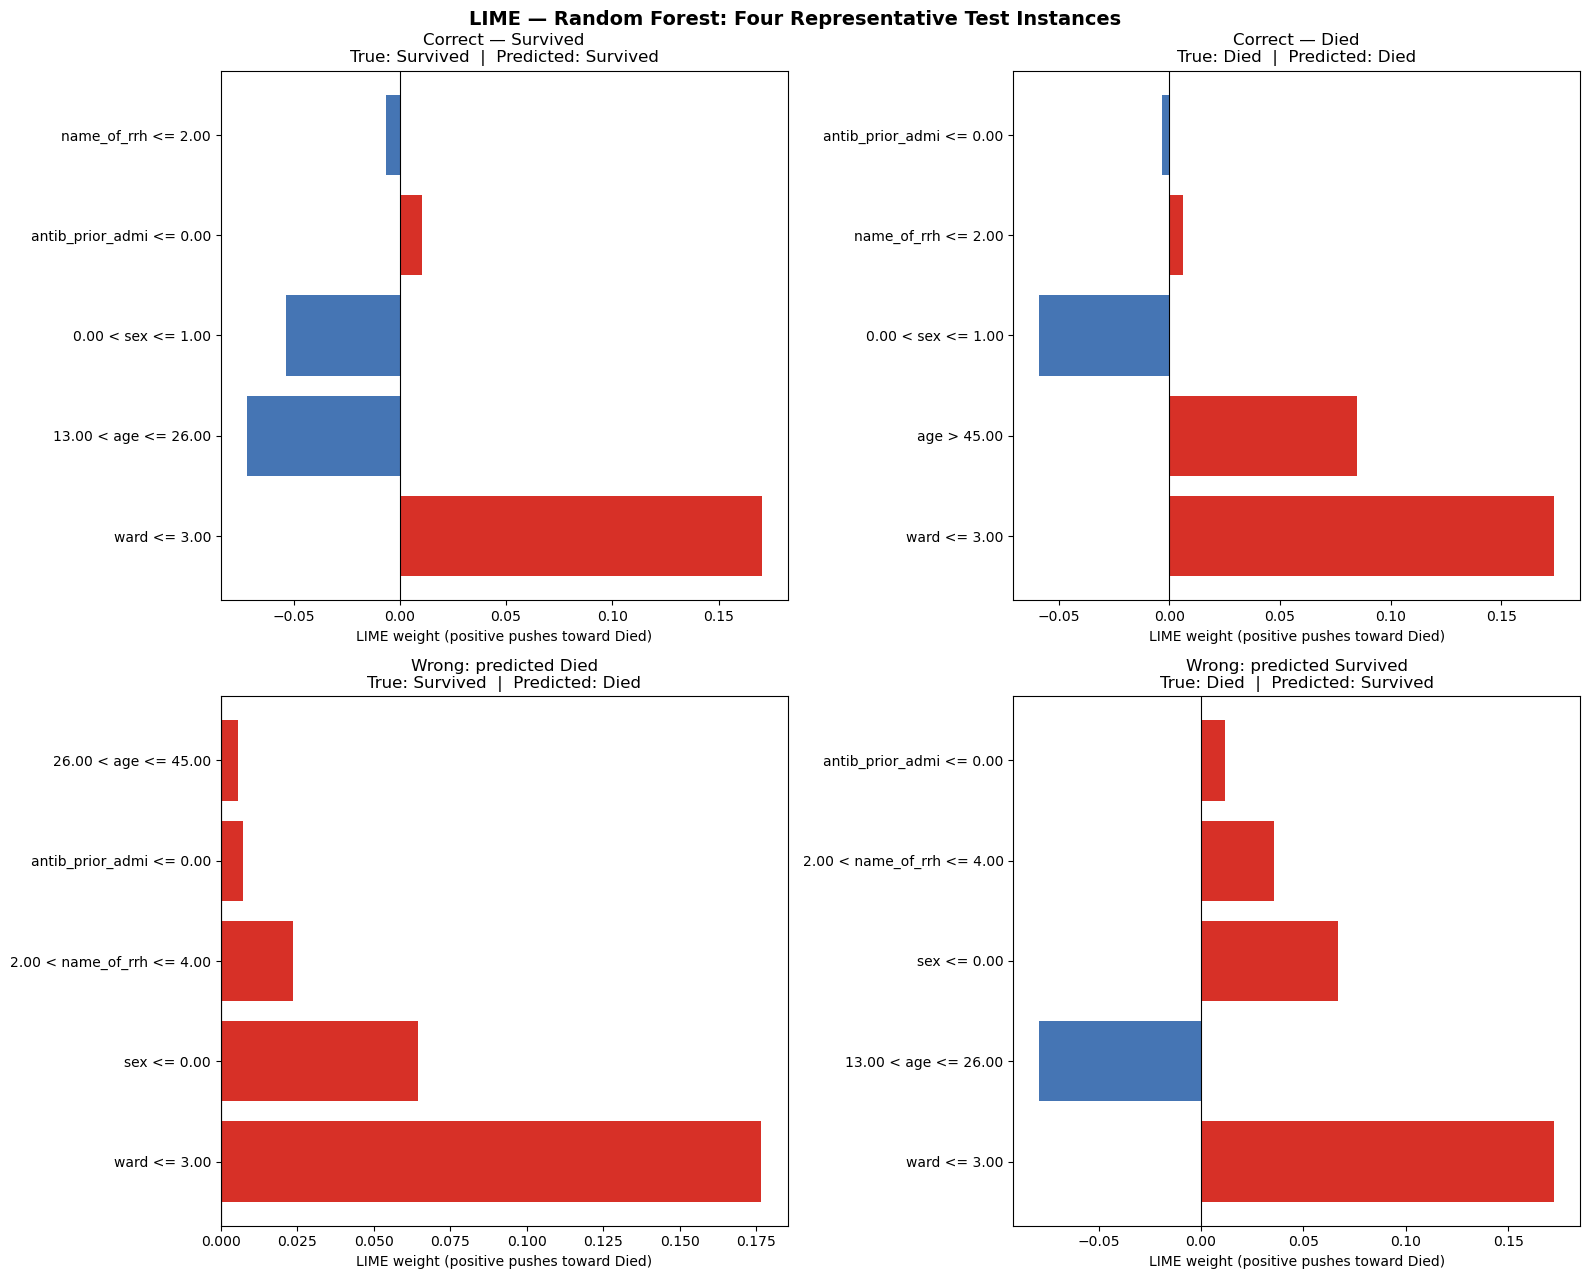

X does not have valid feature names, but LogisticRegression was fitted with feature names
X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but LogisticRegression was fitted with feature names
X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names
X does not have valid feature names, but LogisticRegression was fitted with feature names
X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have 

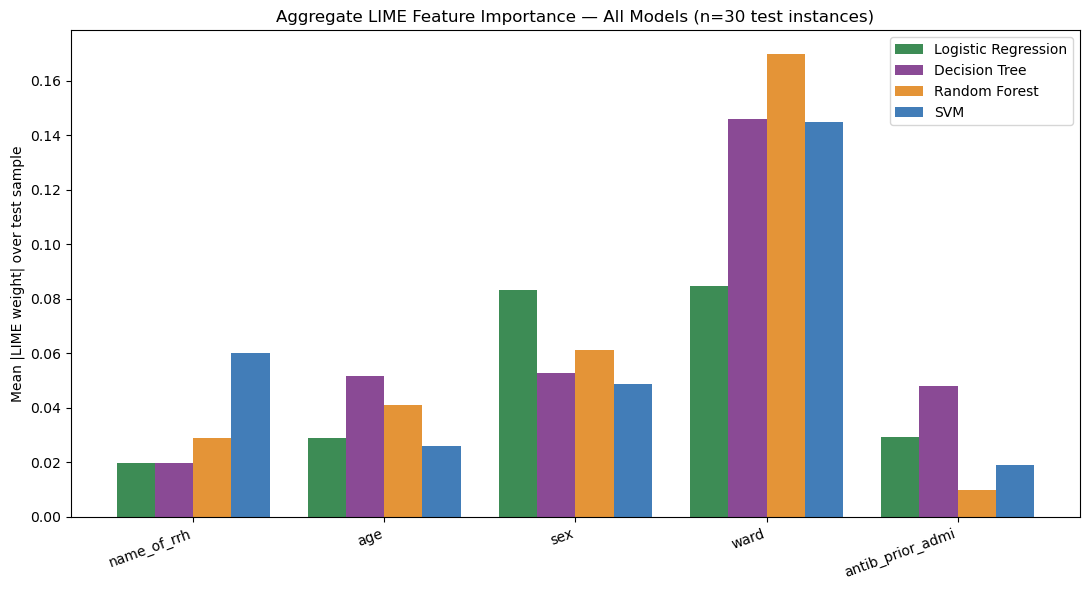

                  Logistic Regression  Decision Tree  Random Forest     SVM
name_of_rrh                    0.0198         0.0199         0.0288  0.0601
age                            0.0290         0.0517         0.0411  0.0260
sex                            0.0832         0.0527         0.0611  0.0489
ward                           0.0847         0.1461         0.1699  0.1450
antib_prior_admi               0.0291         0.0480         0.0100  0.0190


X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassif

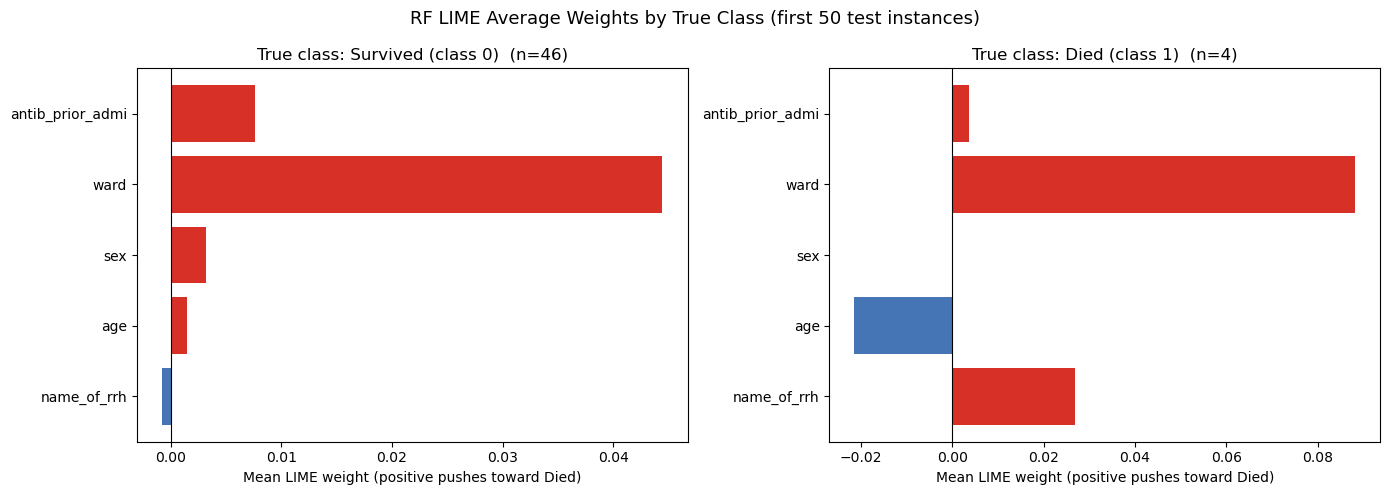

X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names


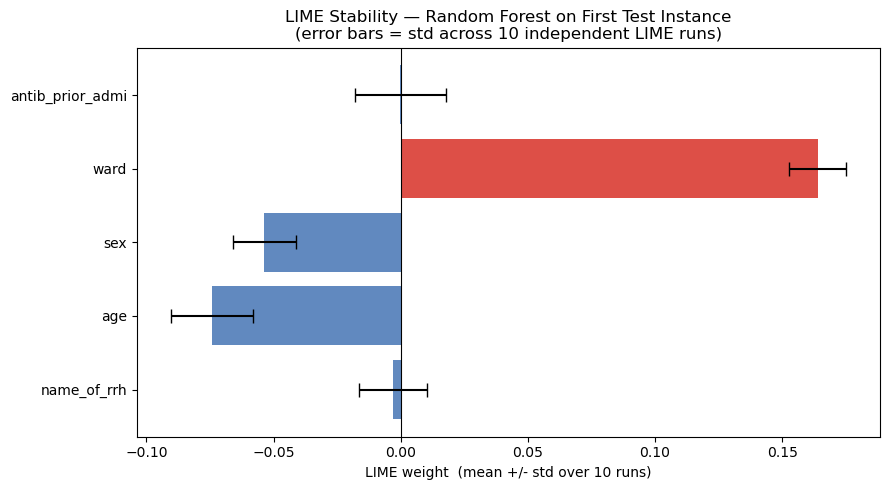

Saved: lime_representative_instances.png | lime_aggregate_importance.png
       lime_per_class_rf.png | lime_stability_rf.png


In [110]:
# ============================================================
# LIME — Extended Visualisations
# 1. Four representative instances (RF)
# 2. Aggregate LIME importance across all models
# 3. Per-class average LIME weights (RF)
# 4. LIME stability — repeated runs on one instance (RF)
# Requires lime_explainer, models_lime, X_test_np, y_test
# ============================================================

y_test_arr = y_test.values

# ----------------------------------------------------------
# 1. LIME for 4 representative RF instances
#    (first correctly predicted: Survived & Died,
#     first incorrectly predicted: Survived & Died)
# ----------------------------------------------------------
rf_preds = rf_model.predict(X_test_np)
correct_survived   = np.where((rf_preds == 0) & (y_test_arr == 0))[0]
correct_died       = np.where((rf_preds == 1) & (y_test_arr == 1))[0]
incorrect_survived = np.where((rf_preds == 1) & (y_test_arr == 0))[0]
incorrect_died     = np.where((rf_preds == 0) & (y_test_arr == 1))[0]

rep_indices = {}
for label, arr in [
    ("Correct — Survived",        correct_survived),
    ("Correct — Died",            correct_died),
    ("Wrong: predicted Died",     incorrect_survived),
    ("Wrong: predicted Survived", incorrect_died),
]:
    rep_indices[label] = int(arr[0]) if len(arr) > 0 else 0

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("LIME — Random Forest: Four Representative Test Instances", fontsize=14, fontweight="bold")

for ax, (label, idx) in zip(axes.flat, rep_indices.items()):
    exp = lime_explainer.explain_instance(
        X_test_np[idx],
        rf_model.predict_proba,
        num_features=len(feature_names),
        labels=(1,)
    )
    vals  = [v for _, v in exp.as_list(label=1)]
    feats = [f for f, _ in exp.as_list(label=1)]
    colors = ["#d73027" if v > 0 else "#4575b4" for v in vals]
    ax.barh(feats, vals, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    true_lbl = "Died" if y_test_arr[idx] == 1 else "Survived"
    pred_lbl = "Died" if rf_preds[idx] == 1 else "Survived"
    ax.set_title(f"{label}\nTrue: {true_lbl}  |  Predicted: {pred_lbl}")
    ax.set_xlabel("LIME weight (positive pushes toward Died)")

plt.tight_layout()
plt.savefig("lime_representative_instances.png", dpi=150, bbox_inches="tight")
plt.show()


# ----------------------------------------------------------
# 2. Aggregate LIME importance — mean |weight| across 30
#    random test instances, for every model
# ----------------------------------------------------------
n_agg = min(30, len(X_test_np))
rng = np.random.default_rng(42)
agg_idx = rng.choice(len(X_test_np), size=n_agg, replace=False)

agg_weights = {name: np.zeros(len(feature_names)) for name in models_lime}

for idx in agg_idx:
    for name, model in models_lime.items():
        if hasattr(model, "predict_proba"):
            pfn = model.predict_proba
        else:
            def pfn(X, m=model):
                scores = m.decision_function(X)
                proba  = 1 / (1 + np.exp(-scores))
                return np.column_stack([1 - proba, proba])
        exp = lime_explainer.explain_instance(
            X_test_np[idx], pfn,
            num_features=len(feature_names), labels=(1,)
        )
        w_dict = dict(exp.as_list(label=1))
        for fi, fname in enumerate(feature_names):
            matched = [v for k, v in w_dict.items() if fname in k]
            agg_weights[name][fi] += abs(matched[0]) if matched else 0.0

for name in agg_weights:
    agg_weights[name] /= n_agg

agg_df = pd.DataFrame(agg_weights, index=feature_names)

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(feature_names))
width = 0.2
palette = ["#1b7837", "#762a83", "#e08214", "#2166ac"]
for i, (model_name, color) in enumerate(zip(agg_df.columns, palette)):
    ax.bar(x + i * width, agg_df[model_name], width, label=model_name, color=color, alpha=0.85)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(feature_names, rotation=20, ha="right")
ax.set_ylabel("Mean |LIME weight| over test sample")
ax.set_title(f"Aggregate LIME Feature Importance — All Models (n={n_agg} test instances)")
ax.legend()
plt.tight_layout()
plt.savefig("lime_aggregate_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(agg_df.round(4).to_string())


# ----------------------------------------------------------
# 3. Per-class average LIME weights — RF
#    Survived instances vs Died instances (first 50 test rows)
# ----------------------------------------------------------
class_weights = {0: np.zeros(len(feature_names)), 1: np.zeros(len(feature_names))}
class_counts  = {0: 0, 1: 0}

for idx in range(min(50, len(X_test_np))):
    true_cls = int(y_test_arr[idx])
    exp = lime_explainer.explain_instance(
        X_test_np[idx], rf_model.predict_proba,
        num_features=len(feature_names), labels=(1,)
    )
    w_dict = dict(exp.as_list(label=1))
    for fi, fname in enumerate(feature_names):
        matched = [v for k, v in w_dict.items() if fname in k]
        class_weights[true_cls][fi] += matched[0] if matched else 0.0
    class_counts[true_cls] += 1

for cls in class_weights:
    if class_counts[cls] > 0:
        class_weights[cls] /= class_counts[cls]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("RF LIME Average Weights by True Class (first 50 test instances)", fontsize=13)
for ax, (cls, lbl) in zip(axes, [(0, "Survived (class 0)"), (1, "Died (class 1)")]):
    w = class_weights[cls]
    colors = ["#d73027" if v > 0 else "#4575b4" for v in w]
    ax.barh(feature_names, w, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"True class: {lbl}  (n={class_counts[cls]})")
    ax.set_xlabel("Mean LIME weight (positive pushes toward Died)")
plt.tight_layout()
plt.savefig("lime_per_class_rf.png", dpi=150, bbox_inches="tight")
plt.show()


# ----------------------------------------------------------
# 4. LIME stability — 10 repeated explanations, same instance
#    Error bars show how consistent LIME weights are (RF)
# ----------------------------------------------------------
n_runs = 10
stability_weights = np.zeros((n_runs, len(feature_names)))

for run in range(n_runs):
    exp = lime_explainer.explain_instance(
        X_test_np[0], rf_model.predict_proba,
        num_features=len(feature_names), labels=(1,),
        num_samples=1000
    )
    w_dict = dict(exp.as_list(label=1))
    for fi, fname in enumerate(feature_names):
        matched = [v for k, v in w_dict.items() if fname in k]
        stability_weights[run, fi] = matched[0] if matched else 0.0

mean_w = stability_weights.mean(axis=0)
std_w  = stability_weights.std(axis=0)
colors = ["#d73027" if v > 0 else "#4575b4" for v in mean_w]

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(feature_names))
ax.barh(y_pos, mean_w, xerr=std_w, color=colors, capsize=5, alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("LIME weight  (mean +/- std over 10 runs)")
ax.set_title("LIME Stability — Random Forest on First Test Instance\n(error bars = std across 10 independent LIME runs)")
plt.tight_layout()
plt.savefig("lime_stability_rf.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved: lime_representative_instances.png | lime_aggregate_importance.png")
print("       lime_per_class_rf.png | lime_stability_rf.png")


In [121]:
# Install libraries needed for the new explainability techniques
!pip install pyale dice-ml alibi


  Obtaining dependency information for pyale from https://files.pythonhosted.org/packages/9c/78/aa9438323df7083f7ec5ff2712ab297faf5fbfbc540abeb868d3c1c50fad/PyALE-1.2.0-py3-none-any.whl.metadata
  Using cached PyALE-1.2.0-py3-none-any.whl.metadata (13 kB)
  Obtaining dependency information for dice-ml from https://files.pythonhosted.org/packages/9a/a2/63c11da0358ac2e931b0ab2e2cf203d9a234beeb201d62708733f7f7eea7/dice_ml-0.12-py3-none-any.whl.metadata
  Using cached dice_ml-0.12-py3-none-any.whl.metadata (20 kB)
  Obtaining dependency information for alibi from https://files.pythonhosted.org/packages/bc/00/bc8caafbabf675a15f08e8cd6d86eedb5949e2cec5ec73157d71f62abd79/alibi-0.9.6-py3-none-any.whl.metadata
  Using cached alibi-0.9.6-py3-none-any.whl.metadata (22 kB)
  Obtaining dependency information for spacy[lookups]<4.0.0,>=2.0.0 from https://files.pythonhosted.org/packages/e1/61/7f7d38e71daac7f91ffd362fb15645b6f9a68ad231e0ed6ff5c1dc6f6930/spacy-3.8.14-cp311-cp311-macosx_11_0_arm64.whl.m

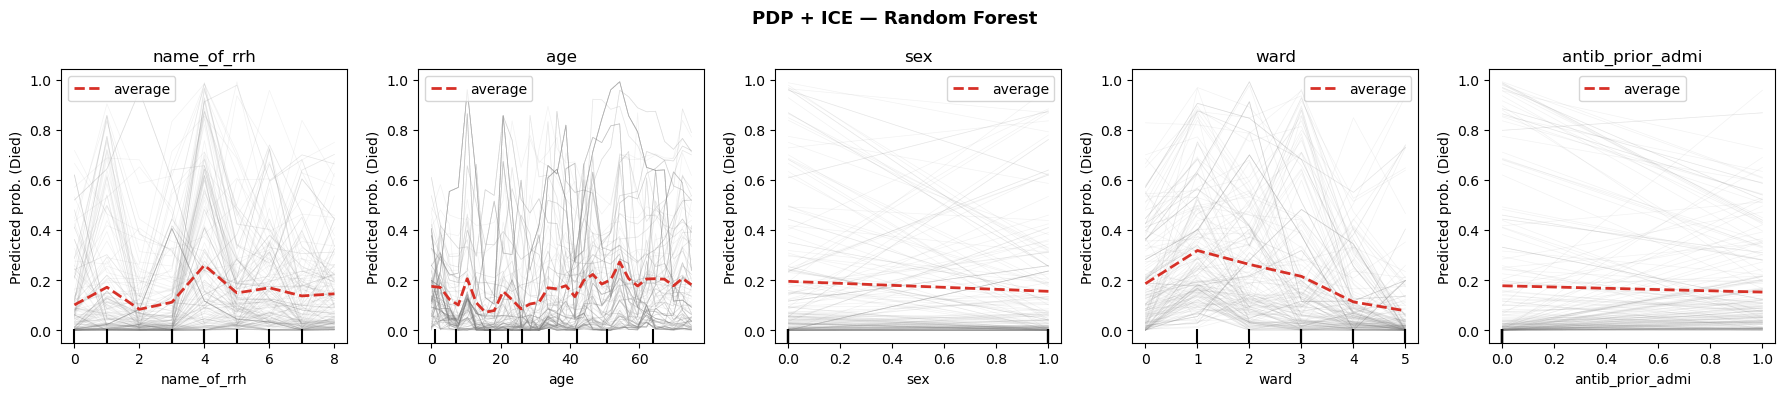

Saved: pdp_ice_random_forest.png


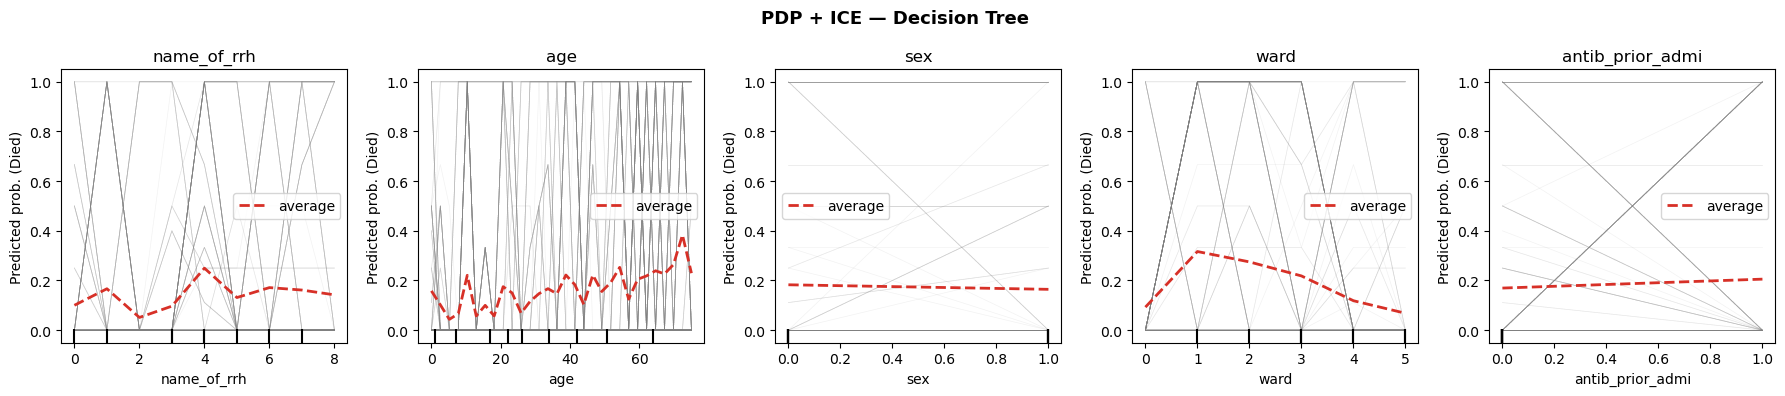

Saved: pdp_ice_decision_tree.png


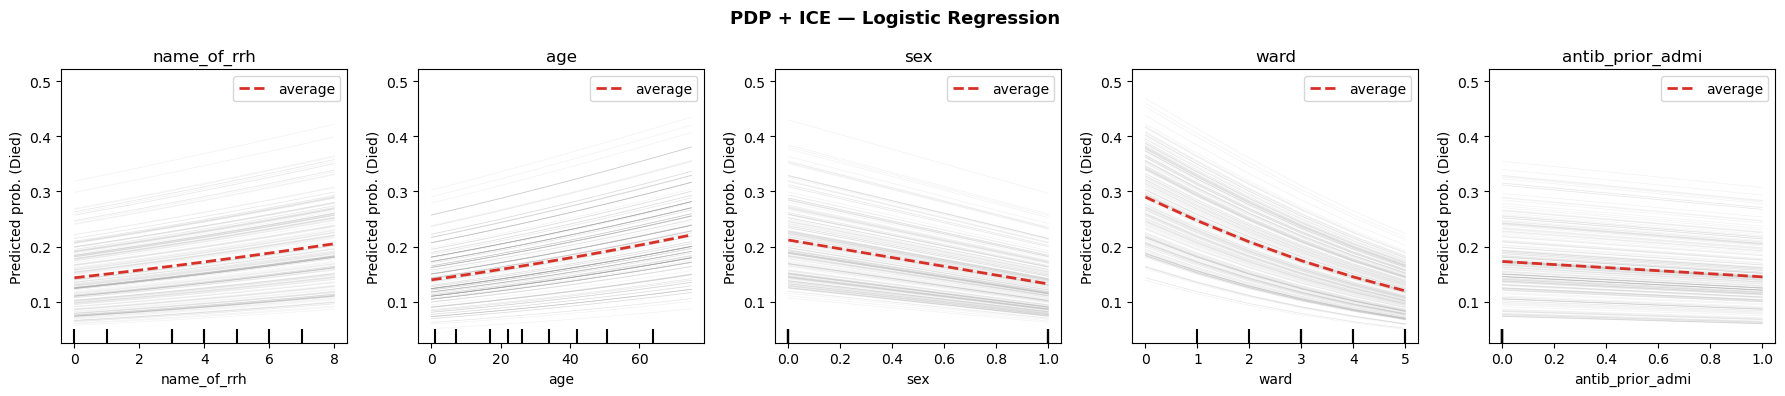

Saved: pdp_ice_logistic_regression.png


In [112]:
# ============================================================
# PARTIAL DEPENDENCE PLOTS (PDP) + INDIVIDUAL CONDITIONAL EXPECTATION (ICE)
#
# HOW IT WORKS:
#   A PDP marginalises out all other features and shows the average predicted
#   probability as one feature varies across its range.  It answers:
#   'Holding everything else constant, how does changing feature X affect the
#   model's predicted mortality probability on average?'
#   ICE lines show the same curve for every individual patient so you can see
#   whether the average (PDP) is masking heterogeneous subgroups.
#
# WHY IT APPLIES HERE:
#   With only 5 features you can plot all of them.  Clinicians can read a
#   PDP like a dose-response curve — e.g. 'as age increases from 20 to 80,
#   predicted mortality risk rises from X to Y'.  Works for RF, DT, and LR;
#   for SVM we use a sigmoid-wrapped version.
# ============================================================

from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt
import pandas as pd

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

# PartialDependenceDisplay needs a DataFrame with named columns
X_test_df  = pd.DataFrame(X_test_np, columns=feature_names)
X_train_df = pd.DataFrame(X_train_np, columns=feature_names)

pdp_models = {
    "Random Forest":       rf_model,
    "Decision Tree":       tree_model,
    "Logistic Regression": LR_model,
}

for model_name, model in pdp_models.items():
    fig, axes = plt.subplots(1, len(feature_names), figsize=(18, 4))
    fig.suptitle(f"PDP + ICE — {model_name}", fontsize=13, fontweight="bold")

    # kind='both' overlays individual ICE lines (grey) under the mean PDP (blue)
    display = PartialDependenceDisplay.from_estimator(
        model,
        X_train_df,
        features=feature_names,
        kind="both",          # 'average' for PDP only, 'individual' for ICE only
        subsample=200,        # use 200 training rows for ICE lines (speed)
        n_jobs=-1,
        grid_resolution=30,
        ax=axes,
        line_kw={"color": "#2166ac"},
        ice_lines_kw={"color": "grey", "alpha": 0.1, "linewidth": 0.5},
        pd_line_kw={"color": "#d73027", "linewidth": 2},
    )
    for ax, fname in zip(axes, feature_names):
        ax.set_title(fname)
        ax.set_xlabel(fname)
        ax.set_ylabel("Predicted prob. (Died)")

    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(f"pdp_ice_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: pdp_ice_{safe_name}.png")


X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but RandomForestClassif

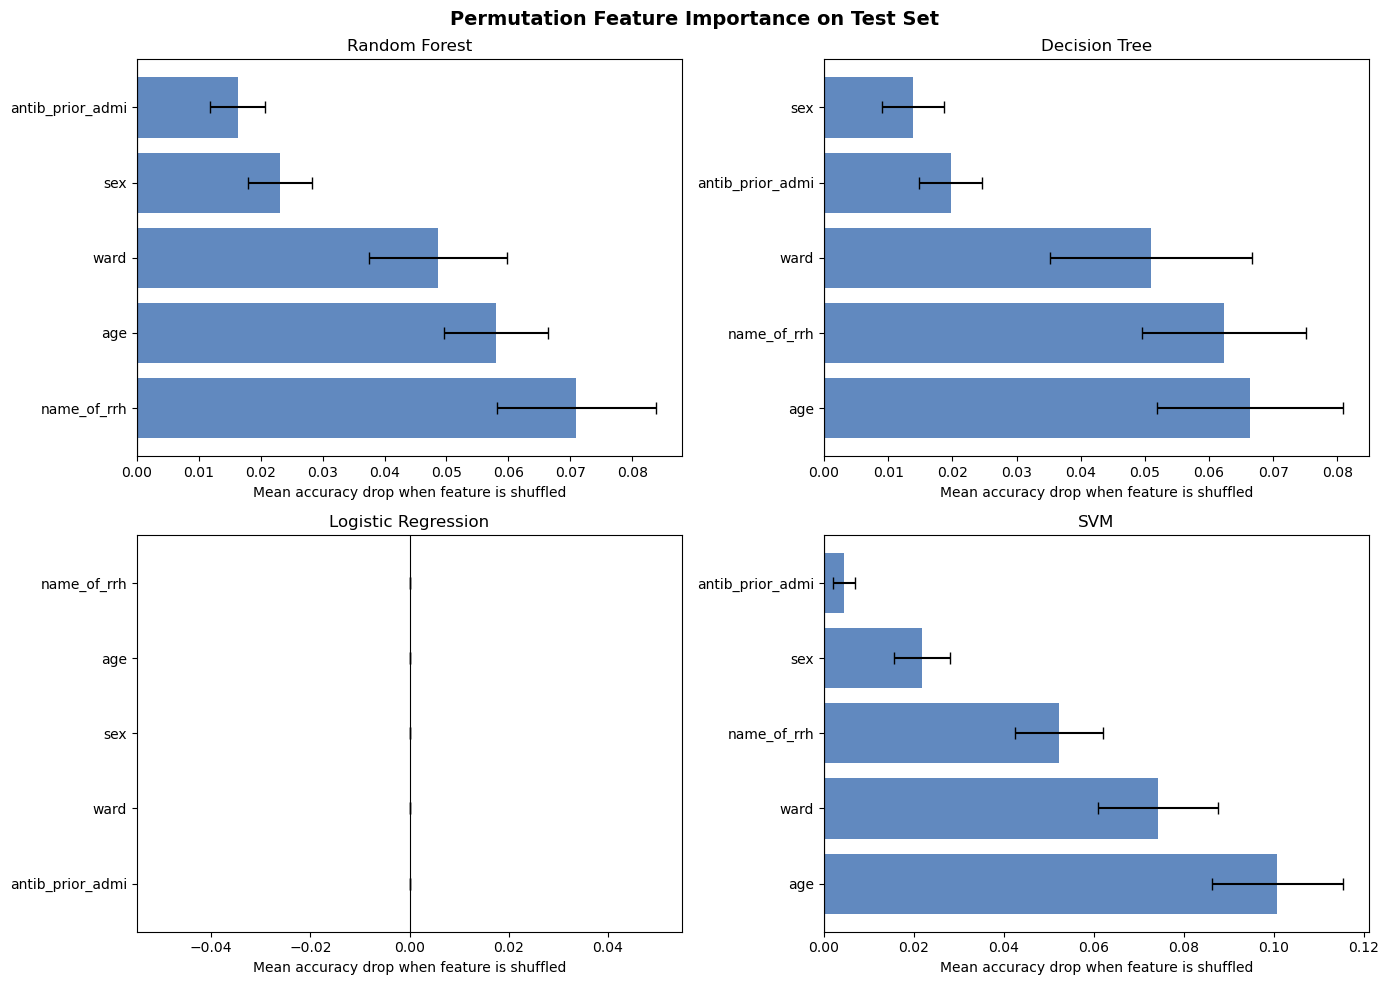

                  Random Forest  Decision Tree  Logistic Regression     SVM
name_of_rrh              0.0710         0.0623                  0.0  0.0522
age                      0.0580         0.0664                  0.0  0.1007
sex                      0.0231         0.0138                  0.0  0.0218
ward                     0.0486         0.0509                  0.0  0.0742
antib_prior_admi         0.0163         0.0197                  0.0  0.0044
Saved: permutation_importance.png | permutation_importance_summary.csv


In [113]:
# ============================================================
# PERMUTATION FEATURE IMPORTANCE
#
# HOW IT WORKS:
#   For each feature in turn, its values are randomly shuffled across the
#   test set — breaking any real relationship between that feature and the
#   outcome.  The drop in a chosen metric (accuracy here) tells you how much
#   the model depended on that feature.  A large drop = the feature matters;
#   near-zero drop = the model barely uses it.
#
# WHY IT APPLIES HERE:
#   Unlike tree-based Gini importance, permutation importance is unbiased and
#   model-agnostic.  It is measured on the *test* set so it reflects
#   generalisation — important when your training data is bootstrapped.
#   Running it for all 4 models and comparing shows whether different
#   algorithms are relying on the same clinical signals.
# ============================================================

from sklearn.inspection import permutation_importance
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

perm_models = {
    "Random Forest":       rf_model,
    "Decision Tree":       tree_model,
    "Logistic Regression": LR_model,
    "SVM":                 svm_model,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Permutation Feature Importance on Test Set", fontsize=14, fontweight="bold")

perm_results = {}
for ax, (name, model) in zip(axes.flat, perm_models.items()):
    # n_repeats: shuffle each feature this many times and average the result
    result = permutation_importance(
        model, X_test_np, y_test.values,
        n_repeats=30, random_state=42, scoring="accuracy"
    )
    perm_results[name] = result

    # Sort features by mean importance (descending)
    order = np.argsort(result.importances_mean)[::-1]
    ax.barh(
        [feature_names[i] for i in order],
        result.importances_mean[order],
        xerr=result.importances_std[order],
        capsize=4,
        color="#4575b4", alpha=0.85
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Mean accuracy drop when feature is shuffled")
    ax.set_title(name)

plt.tight_layout()
plt.savefig("permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# Summary table: mean importance across all models
summary = pd.DataFrame(
    {name: res.importances_mean for name, res in perm_results.items()},
    index=feature_names
)
print(summary.round(4).to_string())
summary.to_csv("permutation_importance_summary.csv")
print("Saved: permutation_importance.png | permutation_importance_summary.csv")


                  Coefficient      OR  OR_lower95  OR_upper95  p_value
Feature                                                               
name_of_rrh            0.0556  1.0571      0.9784      1.1422   0.1594
age                    0.0076  1.0077      0.9999      1.0155   0.0529
sex                   -0.5824  0.5586      0.3802      0.8207   0.0030
ward                  -0.2245  0.7989      0.7092      0.9000   0.0002
antib_prior_admi      -0.2144  0.8070      0.4136      1.5748   0.5296


X does not have valid feature names, but LogisticRegression was fitted with feature names


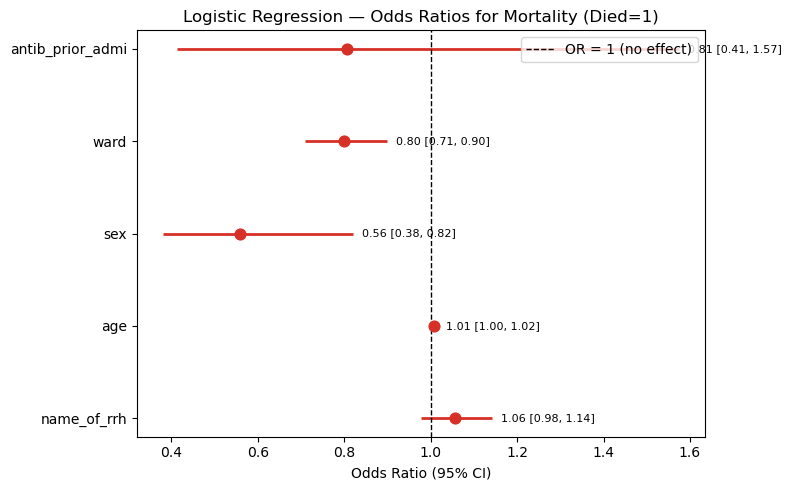

Saved: lr_odds_ratios_forest.png | lr_odds_ratios.csv


In [114]:
# ============================================================
# LOGISTIC REGRESSION COEFFICIENTS AND ODDS RATIOS
#
# HOW IT WORKS:
#   In a logistic regression, each coefficient (beta) represents the change
#   in the log-odds of the outcome per one-unit increase in that feature,
#   holding all others constant.  Exponentiating it gives the Odds Ratio (OR):
#   OR > 1 => feature increases odds of dying; OR < 1 => protective.
#   A 95% confidence interval is computed from the standard errors of the
#   coefficients (derived from the Hessian of the log-likelihood).
#
# WHY IT APPLIES HERE:
#   Odds ratios are the standard effect-size measure in clinical/epidemiology
#   literature.  Presenting them from your LR model gives results directly
#   comparable to the traditional statistical analyses clinicians expect.
#   This is the most interpretable output for a non-ML clinical audience.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

# Extract coefficients from the fitted Logistic Regression
coefs = LR_model.coef_[0]          # shape: (n_features,)
intercept = LR_model.intercept_[0]

# Standard errors via the variance-covariance matrix of the fitted model
# Approximated from the Hessian: Var(beta) = (X^T W X)^{-1}
# where W = diag(p_hat * (1 - p_hat)) on the training data
p_hat = LR_model.predict_proba(X_train_np)[:, 1]
W     = p_hat * (1 - p_hat)
X_aug = np.column_stack([np.ones(len(X_train_np)), X_train_np])   # add intercept column
XTWX  = X_aug.T @ (W[:, None] * X_aug)
try:
    cov_matrix = np.linalg.inv(XTWX)
    se = np.sqrt(np.diag(cov_matrix))[1:]  # drop intercept SE
except np.linalg.LinAlgError:
    # Fallback: use a diagonal approximation if matrix is singular
    se = np.ones(len(coefs)) * 0.1

# 95% CI on the log-odds scale, then exponentiate
z_95    = stats.norm.ppf(0.975)
or_vals = np.exp(coefs)
or_low  = np.exp(coefs - z_95 * se)
or_high = np.exp(coefs + z_95 * se)
p_vals  = 2 * stats.norm.sf(np.abs(coefs / se))

or_df = pd.DataFrame({
    "Feature":    feature_names,
    "Coefficient": coefs,
    "OR":          or_vals,
    "OR_lower95":  or_low,
    "OR_upper95":  or_high,
    "p_value":     p_vals,
}).set_index("Feature")
print(or_df.round(4).to_string())
or_df.to_csv("lr_odds_ratios.csv")

# Forest plot (standard clinical presentation)
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(feature_names))
ax.scatter(or_vals, y_pos, color="#d73027", zorder=3, s=60)
ax.hlines(
    y_pos, or_low, or_high,
    color="#d73027", linewidth=2, zorder=2
)
ax.axvline(1, color="black", linewidth=1, linestyle="--", label="OR = 1 (no effect)")
ax.set_yticks(y_pos)
ax.set_yticklabels(feature_names)
ax.set_xlabel("Odds Ratio (95% CI)")
ax.set_title("Logistic Regression — Odds Ratios for Mortality (Died=1)")
ax.legend()
# Annotate each point with its OR value
for i, (o, lo, hi) in enumerate(zip(or_vals, or_low, or_high)):
    ax.text(hi + 0.02, i, f"{o:.2f} [{lo:.2f}, {hi:.2f}]", va="center", fontsize=8)
plt.tight_layout()
plt.savefig("lr_odds_ratios_forest.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: lr_odds_ratios_forest.png | lr_odds_ratios.csv")


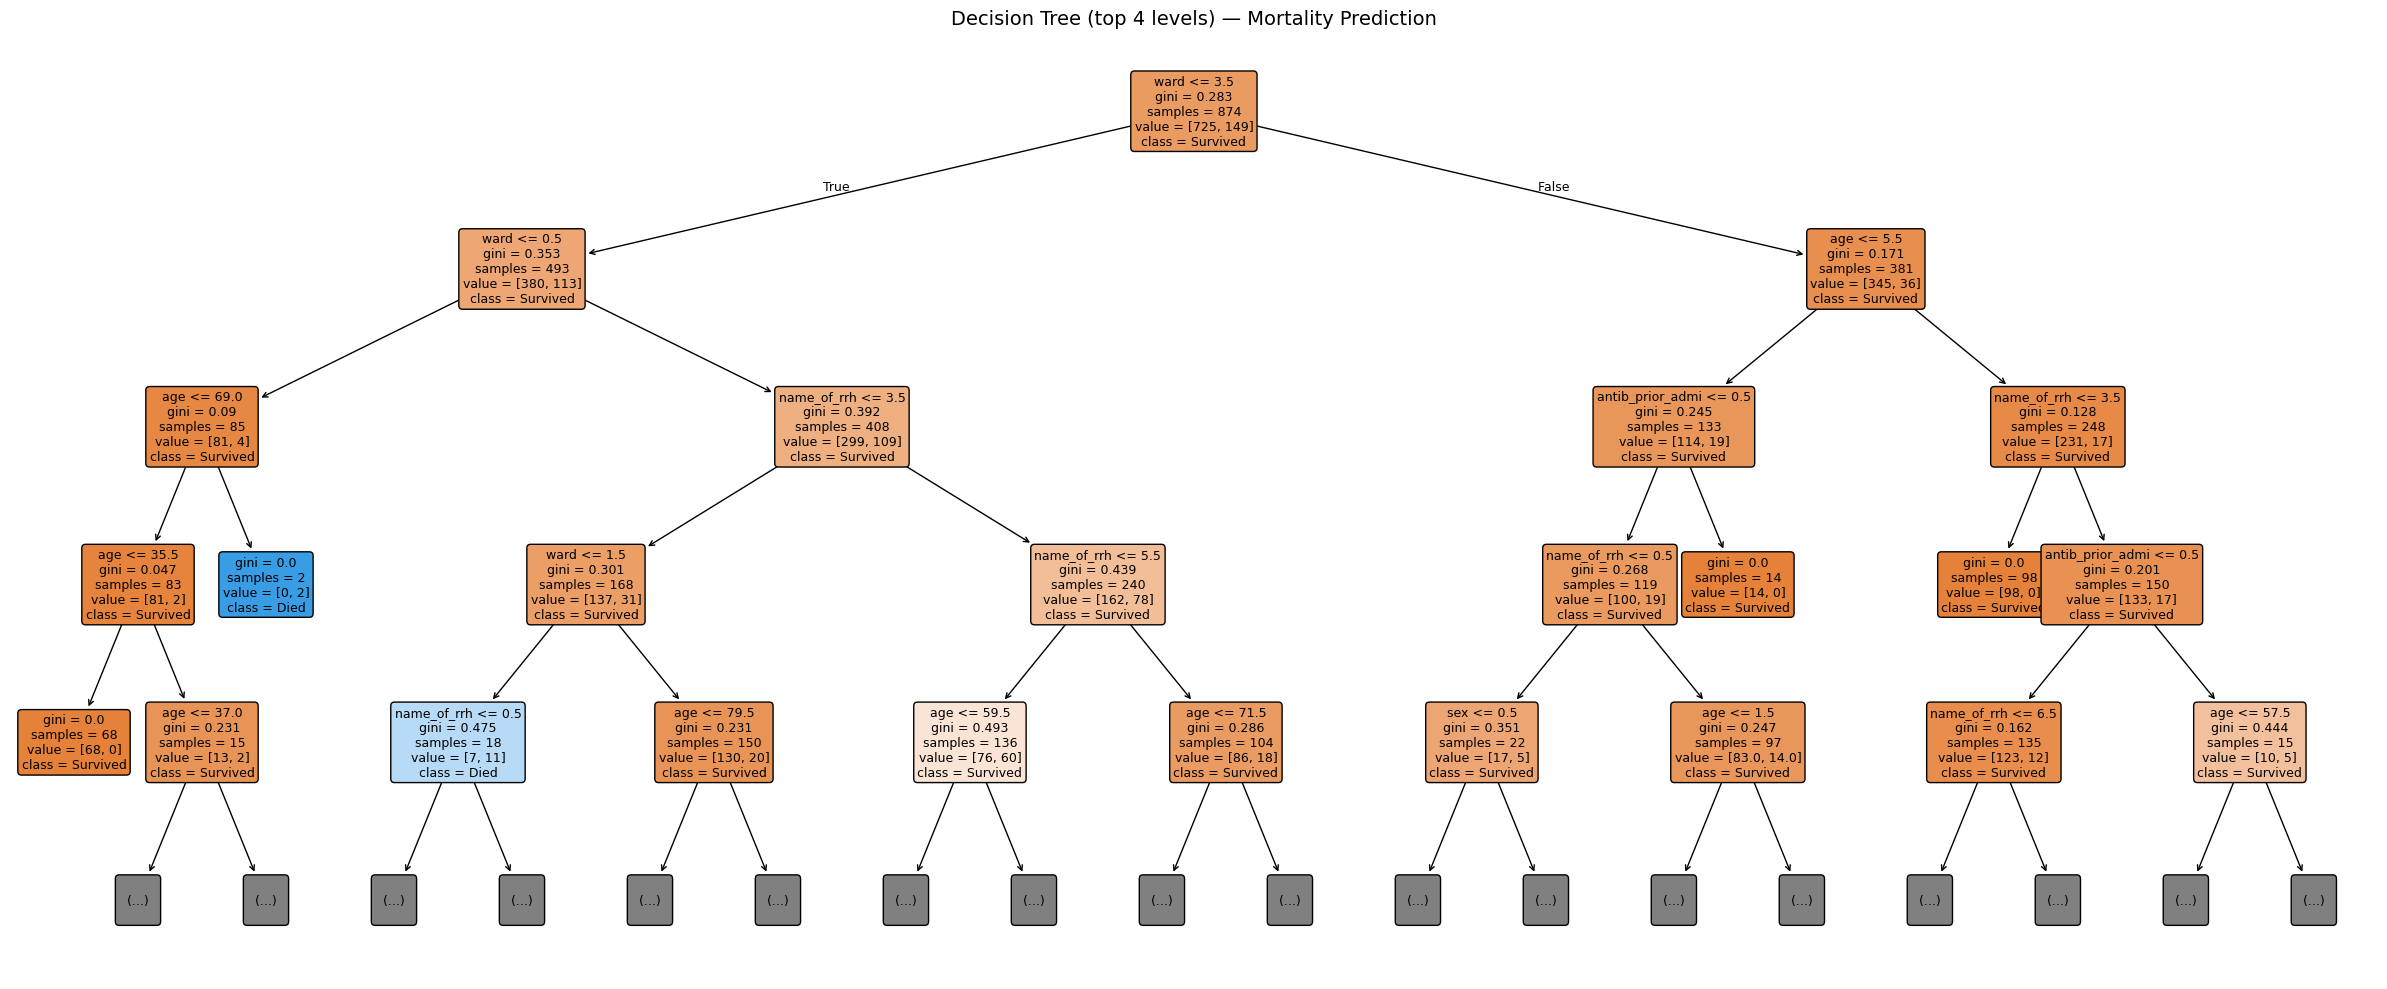

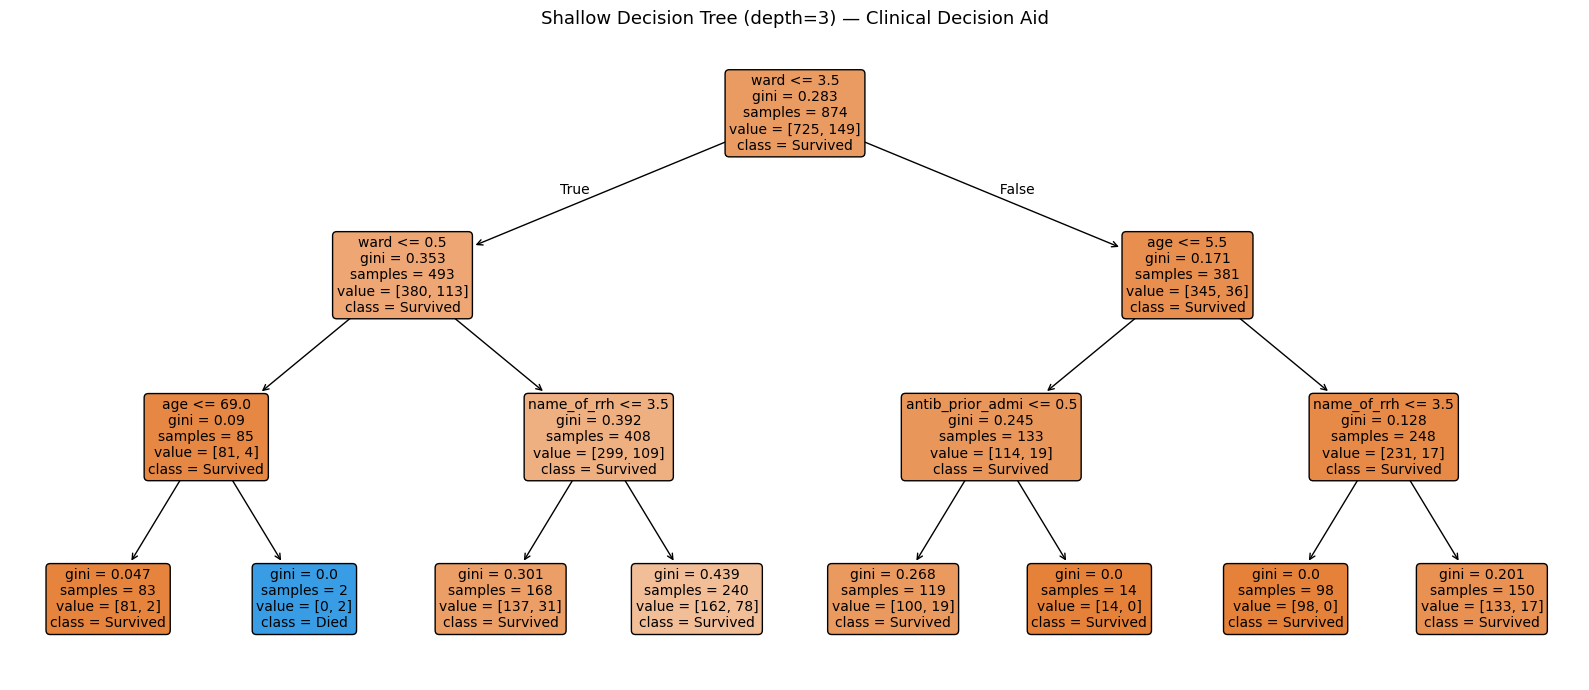

Saved: decision_tree_plot.png | decision_tree_shallow.png | decision_tree_shallow.dot


In [115]:
# ============================================================
# DECISION TREE VISUALISATION
#
# HOW IT WORKS:
#   A Decision Tree partitions the feature space into rectangular regions
#   via a sequence of binary splits.  Visualising the tree shows the exact
#   IF-THEN decision path the model follows from root to leaf.
#   Each node displays: split condition, Gini impurity, sample count,
#   and class distribution — so the logic is fully transparent.
#
# WHY IT APPLIES HERE:
#   The Decision Tree is your most interpretable model by design.  A trimmed
#   (max_depth=4) version gives clinicians a readable decision aid they can
#   follow step by step: 'patients above age X from site Y with prior
#   antibiotics have Z% predicted mortality'.  Also useful to show alongside
#   the RF to illustrate what the ensemble is averaging over.
# ============================================================

from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn import tree as sktree
import matplotlib.pyplot as plt

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]
class_names   = ["Survived", "Died"]

# --- Full tree from last training fold (already fitted) ---
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,          # colour nodes by majority class
    rounded=True,
    max_depth=4,          # show only top 4 levels for readability
    fontsize=9,
    ax=ax,
    impurity=True,        # show Gini impurity at each node
    proportion=False,     # show raw counts not proportions
)
ax.set_title("Decision Tree (top 4 levels) — Mortality Prediction", fontsize=14)
plt.tight_layout()
plt.savefig("decision_tree_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Shallow surrogate re-fitted at depth 3 for maximum clarity ---
shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
shallow_tree.fit(X_train_np, y_train_balanced.values)

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    shallow_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True, rounded=True,
    fontsize=10, ax=ax,
)
ax.set_title("Shallow Decision Tree (depth=3) — Clinical Decision Aid", fontsize=13)
plt.tight_layout()
plt.savefig("decision_tree_shallow.png", dpi=150, bbox_inches="tight")
plt.show()

# Export DOT text for external rendering (e.g. Graphviz)
dot_data = sktree.export_graphviz(
    shallow_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True, rounded=True
)
with open("decision_tree_shallow.dot", "w") as f:
    f.write(dot_data)
print("Saved: decision_tree_plot.png | decision_tree_shallow.png | decision_tree_shallow.dot")


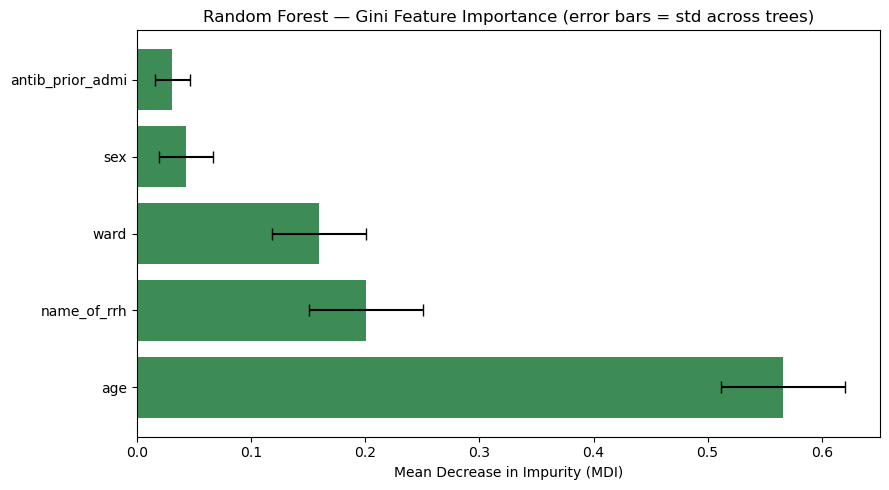

         Feature    MDI  MDI_std
             age 0.5657   0.0542
     name_of_rrh 0.2010   0.0498
            ward 0.1595   0.0413
             sex 0.0431   0.0236
antib_prior_admi 0.0308   0.0154
Saved: rf_gini_importance.png | rf_gini_importance.csv


In [116]:
# ============================================================
# RANDOM FOREST GINI / MDI FEATURE IMPORTANCE
#
# HOW IT WORKS:
#   Each split in a Decision Tree reduces node impurity (measured by Gini).
#   MDI (Mean Decrease in Impurity) sums up those reductions weighted by the
#   number of samples that reach each node, averaged across all trees in the
#   forest.  The result is a fast, built-in importance score.
#   We also plot the per-tree variance as error bars to show stability.
#
# WHY IT APPLIES HERE:
#   MDI is fast and already computed during training — zero extra cost.
#   Plotting it alongside permutation importance and SHAP lets you cross-
#   validate which features are consistently important across methods.
#   Known bias: MDI tends to over-rank high-cardinality features like
#   name_of_rrh; that is worth noting when reporting results.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

# importances_: mean MDI across all trees in the forest
importances = rf_model.feature_importances_

# Per-tree importances for error bars
tree_importances = np.array([t.feature_importances_ for t in rf_model.estimators_])
std_imp = tree_importances.std(axis=0)

order = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    [feature_names[i] for i in order],
    importances[order],
    xerr=std_imp[order],
    capsize=4,
    color="#1b7837", alpha=0.85
)
ax.set_xlabel("Mean Decrease in Impurity (MDI)")
ax.set_title("Random Forest — Gini Feature Importance (error bars = std across trees)")
plt.tight_layout()
plt.savefig("rf_gini_importance.png", dpi=150, bbox_inches="tight")
plt.show()

mdi_df = pd.DataFrame({"Feature": feature_names, "MDI": importances, "MDI_std": std_imp})
mdi_df = mdi_df.sort_values("MDI", ascending=False)
print(mdi_df.round(4).to_string(index=False))
mdi_df.to_csv("rf_gini_importance.csv", index=False)
print("Saved: rf_gini_importance.png | rf_gini_importance.csv")


X does not have valid feature names, but RandomForestClassifier was fitted with feature names
X does not have valid feature names, but SVC was fitted with feature names


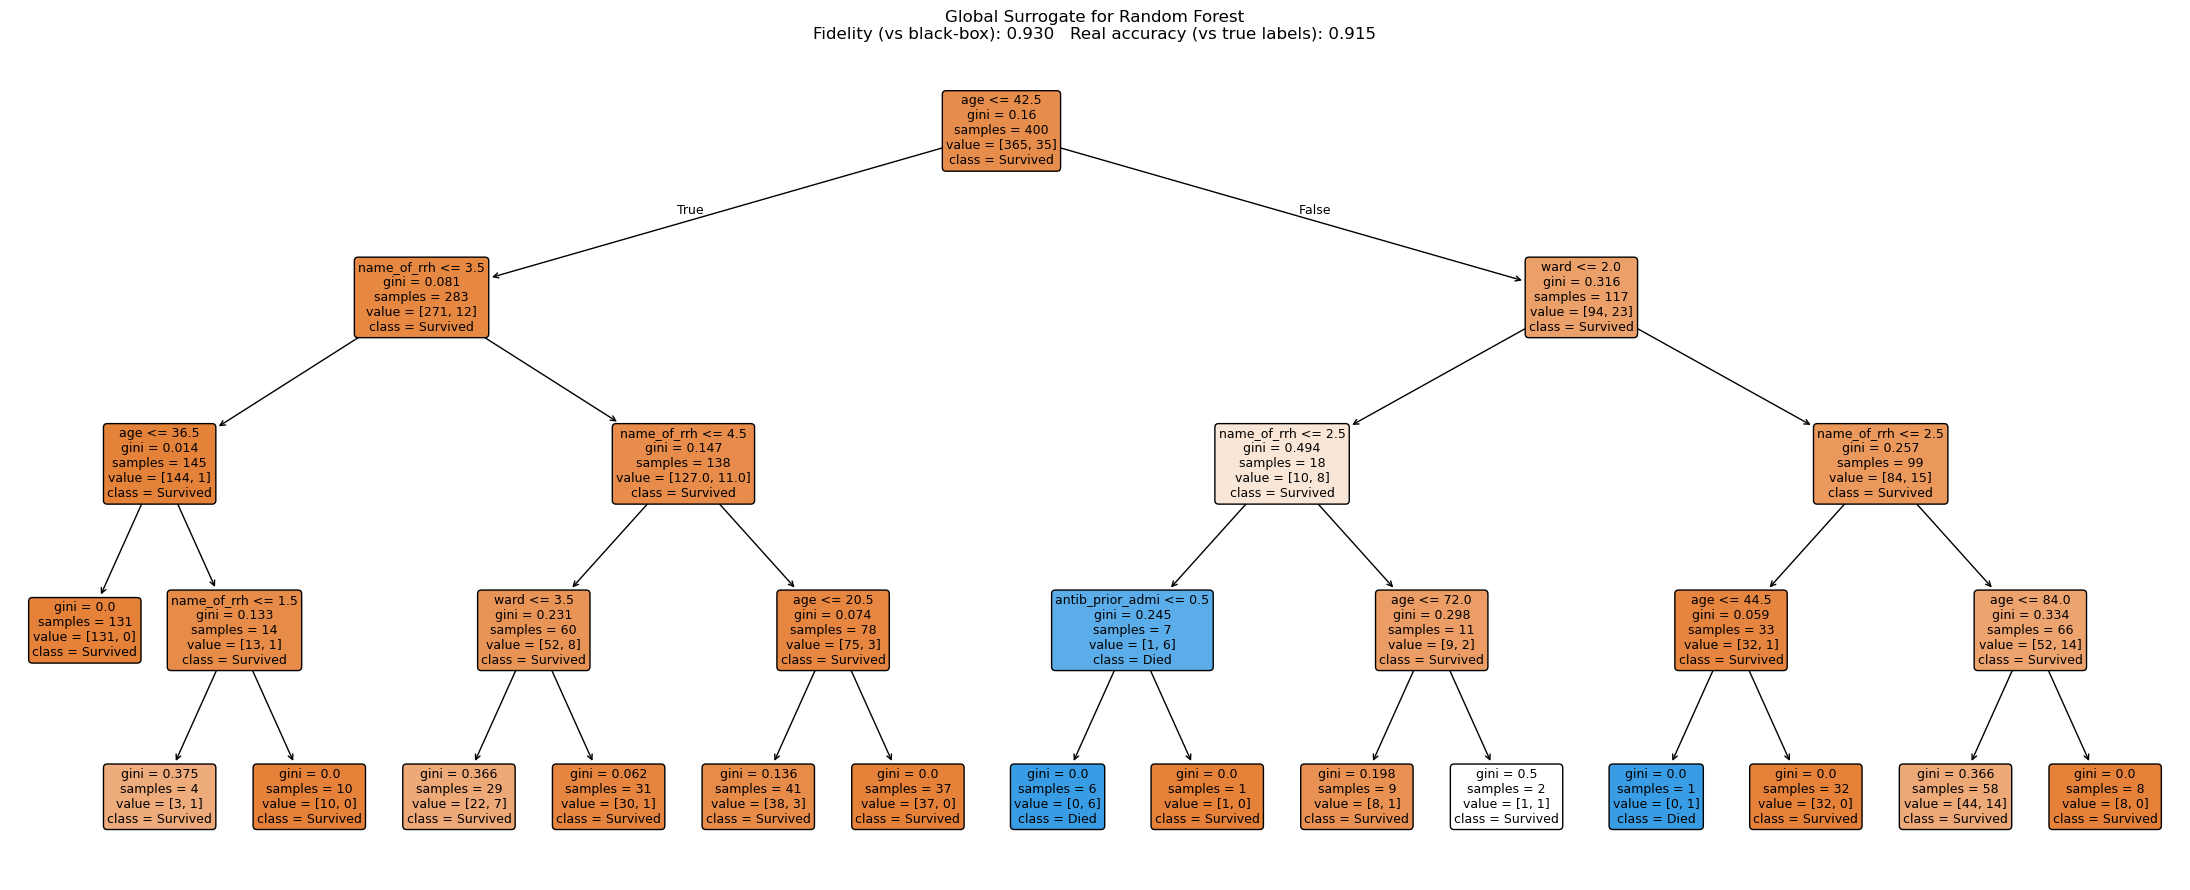

Random Forest surrogate — fidelity: 0.930, real accuracy: 0.915


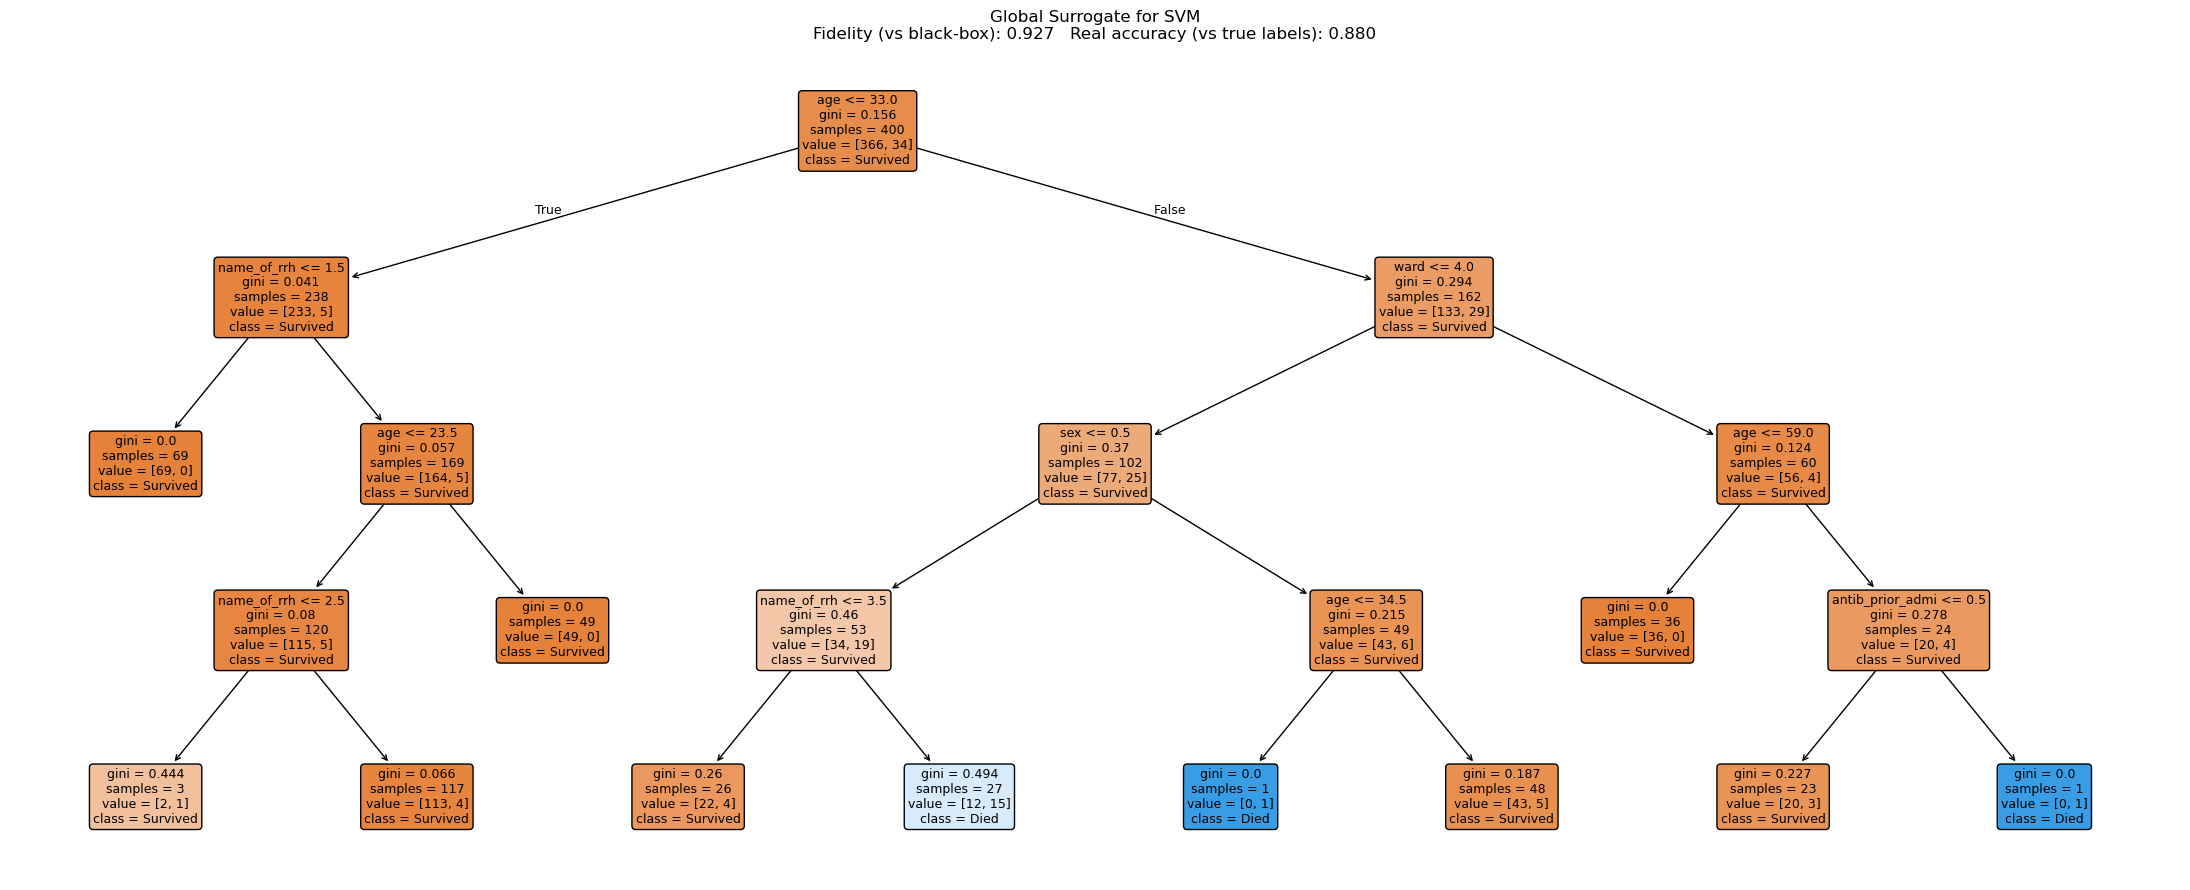

SVM surrogate — fidelity: 0.927, real accuracy: 0.880
Saved: surrogate_random_forest.png | surrogate_svm.png


In [117]:
# ============================================================
# GLOBAL SURROGATE MODEL
#
# HOW IT WORKS:
#   A simple interpretable model (Decision Tree) is trained NOT on the
#   real labels but on the *predictions* of a black-box model (RF or SVM).
#   If the surrogate achieves high fidelity (accuracy vs the black box's
#   outputs), it approximates the black box's decision boundary with a
#   transparent structure you can inspect and explain.
#   Fidelity = accuracy of surrogate against the black box's predictions
#   (not against true labels).
#
# WHY IT APPLIES HERE:
#   RF and SVM are your highest-performing but least transparent models.
#   A surrogate tree condenses what the RF 'learned' into a single flowchart
#   that a clinician can follow and challenge.  Low fidelity would mean the
#   surrogate misses important non-linear structure, which is worth reporting.
# ============================================================

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]
class_names   = ["Survived", "Died"]

surrogate_targets = {
    "Random Forest": rf_model.predict(X_test_np),
    "SVM":           svm_model.predict(X_test_np),
}

for bb_name, bb_preds in surrogate_targets.items():
    # Train surrogate on the full test set using black-box predictions as labels
    surrogate = DecisionTreeClassifier(max_depth=4, random_state=42)
    surrogate.fit(X_test_np, bb_preds)

    # Fidelity: how well the surrogate reproduces the black-box outputs
    fidelity = accuracy_score(bb_preds, surrogate.predict(X_test_np))
    # Real accuracy: how well surrogate predicts the ground truth
    real_acc  = accuracy_score(y_test.values, surrogate.predict(X_test_np))

    fig, ax = plt.subplots(figsize=(22, 9))
    plot_tree(
        surrogate,
        feature_names=feature_names,
        class_names=class_names,
        filled=True, rounded=True,
        max_depth=4, fontsize=9, ax=ax,
    )
    ax.set_title(
        f"Global Surrogate for {bb_name}\n"
        f"Fidelity (vs black-box): {fidelity:.3f}   "
        f"Real accuracy (vs true labels): {real_acc:.3f}",
        fontsize=12
    )
    plt.tight_layout()
    safe = bb_name.lower().replace(" ", "_")
    plt.savefig(f"surrogate_{safe}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{bb_name} surrogate — fidelity: {fidelity:.3f}, real accuracy: {real_acc:.3f}")

print("Saved: surrogate_random_forest.png | surrogate_svm.png")


In [122]:
# ============================================================
# ACCUMULATED LOCAL EFFECTS (ALE) PLOTS
#
# HOW IT WORKS:
#   ALE plots estimate the effect of a feature by measuring prediction
#   differences *within narrow value intervals* rather than over the full
#   marginal distribution like PDPs.  This eliminates extrapolation bias
#   that PDPs suffer when features are correlated.
#   The ALE value at a point x shows: 'in the neighbourhood of x, how much
#   does the prediction change when this feature is varied?'
#
# WHY IT APPLIES HERE:
#   Features like age and ward may be correlated (older patients go to ICU).
#   PDPs would extrapolate into impossible combinations; ALE stays in the
#   observed data manifold.  Use ALE as the more rigorous companion to PDP.
# ============================================================

try:
    from PyALE import ale
    import pandas as pd
    import matplotlib.pyplot as plt

    feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]
    X_test_df = pd.DataFrame(X_test_np, columns=feature_names)

    # PyALE requires a predict function that returns a 1-D array of predictions
    ale_models = {
        "Random Forest":       lambda X: rf_model.predict_proba(X)[:, 1],
        "Logistic Regression": lambda X: LR_model.predict_proba(X)[:, 1],
    }

    # Continuous features only; binary features (sex) skipped
    cont_features = ["age", "name_of_rrh", "ward", "antib_prior_admi"]

    for model_name, predict_fn in ale_models.items():
        fig, axes = plt.subplots(1, len(cont_features), figsize=(16, 4))
        fig.suptitle(f"ALE Plots — {model_name}", fontsize=13, fontweight="bold")

        for ax, feat in zip(axes, cont_features):
            # ale() returns a DataFrame of the ALE curve
            ale_df = ale(
                X=X_test_df,
                model=predict_fn,
                feature=[feat],
                grid_size=20,
                include_CI=True,
                C=0.95,
            )
            ax.plot(ale_df.index, ale_df["eff"], color="#d73027", linewidth=2)
            if "lowerCI_95%" in ale_df.columns:
                ax.fill_between(
                    ale_df.index,
                    ale_df["lowerCI_95%"],
                    ale_df["upperCI_95%"],
                    alpha=0.2, color="#d73027"
                )
            ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
            ax.set_xlabel(feat)
            ax.set_ylabel("ALE (change in predicted prob.)")
            ax.set_title(feat)

        plt.tight_layout()
        safe = model_name.lower().replace(" ", "_")
        plt.savefig(f"ale_{safe}.png", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved: ale_{safe}.png")

except ImportError:
    print("PyALE not available — run: pip install pyale")


Exception: The passed model does not seem to have a predict method.

In [ ]:
# ============================================================
# COUNTERFACTUAL EXPLANATIONS (DiCE)
#
# HOW IT WORKS:
#   A counterfactual asks: 'What is the smallest change to this patient's
#   features that would flip the model's prediction from Died to Survived?'
#   DiCE (Diverse Counterfactual Explanations) generates multiple diverse
#   counterfactuals so you see several plausible alternative scenarios.
#   It works by optimising: minimise feature changes while crossing the
#   decision boundary.
#
# WHY IT APPLIES HERE:
#   Counterfactuals are actionable for clinicians: instead of 'age drove
#   this prediction' (which can't be changed), they show 'if this patient
#   had been admitted to a different ward and had no prior antibiotics, they
#   would be predicted to survive'.  This directly supports treatment and
#   care pathway decisions.
# ============================================================

try:
    import dice_ml
    from dice_ml import Dice
    import pandas as pd
    import matplotlib.pyplot as plt

    feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

    # Build a combined DataFrame needed by DiCE
    train_df = pd.DataFrame(X_train_np, columns=feature_names)
    train_df["treatment_outcome"] = y_train_balanced.values

    # DiCE needs to know which features are continuous vs categorical
    d = dice_ml.Data(
        dataframe=train_df,
        continuous_features=["age"],
        outcome_name="treatment_outcome"
    )

    # Wrap the RF model
    m = dice_ml.Model(model=rf_model, backend="sklearn")
    exp_dice = Dice(d, m, method="random")

    # Find test instances predicted as Died (class 1) to explain
    test_df = pd.DataFrame(X_test_np, columns=feature_names)
    died_predicted = test_df[rf_model.predict(X_test_np) == 1].head(3)

    # Generate 3 diverse counterfactuals per instance
    cf = exp_dice.generate_counterfactuals(
        died_predicted,
        total_CFs=3,
        desired_class="opposite",   # flip to Survived
        random_seed=42,
    )
    cf.visualize_as_dataframe(show_only_changes=True)

    # Save counterfactual table to CSV
    rows = []
    for i, cf_example in enumerate(cf.cf_examples_list):
        df_cf = cf_example.final_cfs_df
        if df_cf is not None:
            df_cf.insert(0, "instance", i)
            rows.append(df_cf)
    if rows:
        cf_all = pd.concat(rows, ignore_index=True)
        cf_all.to_csv("counterfactuals_rf.csv", index=False)

        # Visualise feature changes for first instance
        orig = died_predicted.iloc[[0]]
        cfs  = cf.cf_examples_list[0].final_cfs_df[feature_names]

        fig, ax = plt.subplots(figsize=(10, 5))
        x = range(len(feature_names))
        ax.bar([i - 0.2 for i in x], orig.values[0], 0.4,
               label="Original (predicted Died)", color="#d73027", alpha=0.8)
        ax.bar([i + 0.2 for i in x], cfs.iloc[0].values, 0.4,
               label="Counterfactual (predicted Survived)", color="#4575b4", alpha=0.8)
        ax.set_xticks(list(x))
        ax.set_xticklabels(feature_names, rotation=20, ha="right")
        ax.set_ylabel("Feature value")
        ax.set_title("DiCE Counterfactual — first instance\n(what would need to change to predict Survived)")
        ax.legend()
        plt.tight_layout()
        plt.savefig("counterfactuals_rf.png", dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved: counterfactuals_rf.png | counterfactuals_rf.csv")
    else:
        print("DiCE found no valid counterfactuals for the selected instances.")

except ImportError:
    print("dice-ml not available — run: pip install dice-ml")
except Exception as e:
    print(f"DiCE error: {e}")


dice-ml not available — run: pip install dice-ml


In [ ]:
# ============================================================
# ANCHOR EXPLANATIONS
#
# HOW IT WORKS:
#   An anchor is a set of IF-THEN rules that 'anchor' a prediction with
#   high precision.  Example: 'IF age > 55 AND ward = ICU THEN the model
#   predicts Died with >= 95% precision, regardless of other features.'
#   Unlike LIME which gives a linear approximation, anchors give a
#   coverage-bounded rule that holds for a neighbourhood around the instance.
#   Precision: how often the rule correctly predicts the outcome in that
#   neighbourhood.  Coverage: what fraction of the test space the rule applies to.
#
# WHY IT APPLIES HERE:
#   Anchor rules map directly to clinical criteria — they are the closest
#   XAI output to an actual triage protocol or early-warning score.
#   A high-precision, high-coverage anchor like 'prior antibiotics AND
#   ICU ward => predicted Died' could be proposed as a clinical flag.
# ============================================================

try:
    from alibi.explainers import AnchorTabular
    import numpy as np
    import matplotlib.pyplot as plt
    import pandas as pd

    feature_names = ["name_of_rrh", "age", "sex", "ward", "antib_prior_admi"]

    # AnchorTabular works with predict functions that return class indices
    anchor_explainer = AnchorTabular(
        predictor=rf_model.predict,
        feature_names=feature_names,
    )
    # fit() uses the training data to learn category bins for discretisation
    anchor_explainer.fit(X_train_np, disc_perc=(25, 50, 75))

    # Explain up to 5 test instances (anchors can be slow)
    n_explain = min(5, len(X_test_np))
    records   = []

    for idx in range(n_explain):
        explanation = anchor_explainer.explain(
            X_test_np[idx],
            threshold=0.90,   # require >= 90% precision
        )
        true_lbl = "Died" if y_test.values[idx] == 1 else "Survived"
        pred_lbl = "Died" if rf_model.predict(X_test_np[[idx]])[0] == 1 else "Survived"
        anchor_rule = " AND ".join(explanation.data["anchor"])
        precision   = explanation.data["precision"]
        coverage    = explanation.data["coverage"]
        records.append({
            "Instance": idx,
            "True": true_lbl,
            "Predicted": pred_lbl,
            "Anchor rule": anchor_rule,
            "Precision": round(precision, 3),
            "Coverage":  round(coverage,  3),
        })
        print(f"Instance {idx} | True: {true_lbl} | Pred: {pred_lbl}")
        print(f"  Rule:      {anchor_rule}")
        print(f"  Precision: {precision:.3f}   Coverage: {coverage:.3f}\n")

    anchor_df = pd.DataFrame(records)
    anchor_df.to_csv("anchors_rf.csv", index=False)

    # Bar chart: precision and coverage per instance
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(anchor_df))
    ax.bar(x - 0.2, anchor_df["Precision"], 0.4, label="Precision",  color="#d73027", alpha=0.85)
    ax.bar(x + 0.2, anchor_df["Coverage"],  0.4, label="Coverage",   color="#4575b4", alpha=0.85)
    ax.axhline(0.9, color="grey", linestyle="--", linewidth=1, label="90% threshold")
    ax.set_xticks(x)
    ax.set_xticklabels([f"Inst {i}" for i in anchor_df["Instance"]])
    ax.set_ylabel("Score")
    ax.set_title("Anchor Explanations — Precision and Coverage per Instance (RF)")
    ax.legend()
    plt.tight_layout()
    plt.savefig("anchors_rf.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: anchors_rf.png | anchors_rf.csv")

except ImportError:
    print("alibi not available — run: pip install alibi")
except Exception as e:
    print(f"Anchor error: {e}")


alibi not available — run: pip install alibi


X does not have valid feature names, but RandomForestClassifier was fitted with feature names
Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


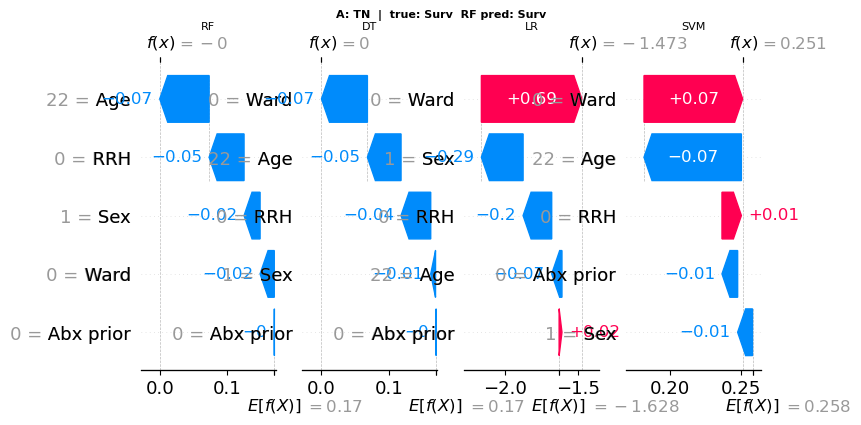

Saved: shap_waterfall_a_tn.png


Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


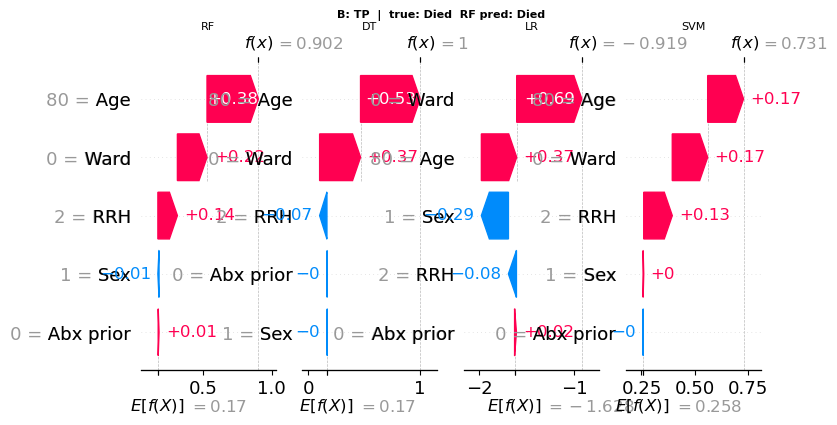

Saved: shap_waterfall_b_tp.png


Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


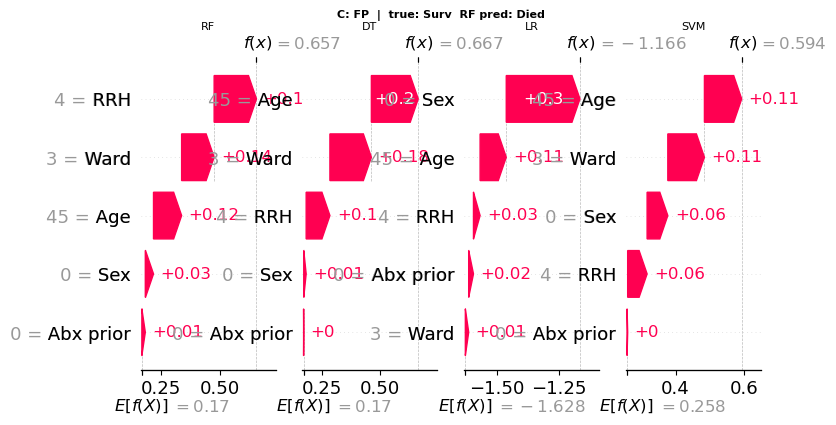

Saved: shap_waterfall_c_fp.png


Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


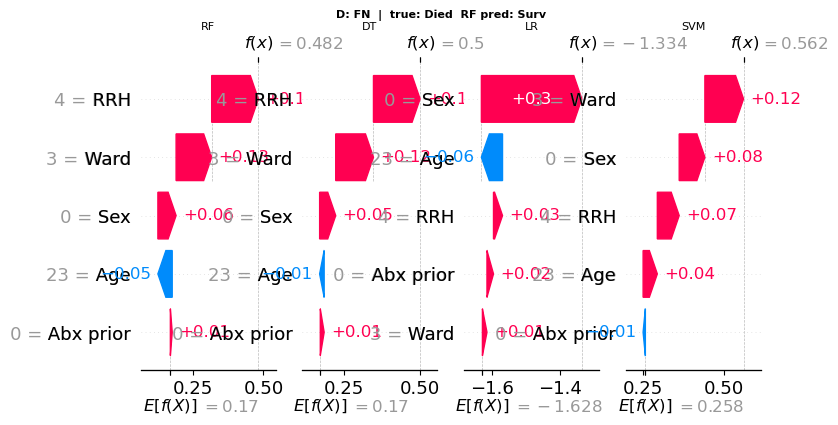

Saved: shap_waterfall_d_fn.png


Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations


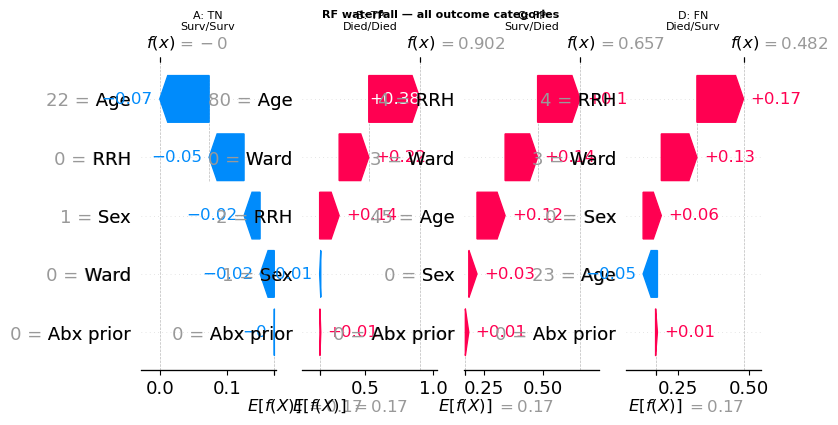

Saved: shap_waterfall_rf_all_categories.png


In [140]:
# ============================================================
# SHAP WATERFALL PLOTS — Extended Examples by Outcome Type
#
# HOW IT WORKS:
#   Each bar shows how a single feature pushes the prediction away
#   from the base value (average training output): red = toward Died,
#   blue = toward Survived.  Four clinically meaningful cases are shown:
#   (A) True Negative — correctly predicted Survived
#   (B) True Positive — correctly predicted Died
#   (C) False Positive — predicted Died, actually Survived
#   (D) False Negative — predicted Survived, actually Died
# ============================================================

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import shap

# Shortened feature names to avoid bar-label crowding
feat_short = ["RRH", "Age", "Sex", "Ward", "Abx prior"]
# Abbreviated model names for subplot titles
model_abbrev = {"Random Forest": "RF", "Decision Tree": "DT",
                "Logistic Regression": "LR", "SVM": "SVM"}

y_arr    = y_test.values
rf_preds = rf_model.predict(X_test_np)

def get_shap1(shap_vals, explainer):
    if isinstance(shap_vals, list):
        sv = shap_vals[1]
        ev = explainer.expected_value[1] if hasattr(explainer.expected_value, "__len__") else explainer.expected_value
    else:
        sv = shap_vals
        ev = explainer.expected_value if not hasattr(explainer.expected_value, "__len__") else float(np.array(explainer.expected_value).flat[-1])
    return sv, float(ev)

categories = {
    "A: TN": np.where((rf_preds == 0) & (y_arr == 0))[0],
    "B: TP": np.where((rf_preds == 1) & (y_arr == 1))[0],
    "C: FP": np.where((rf_preds == 1) & (y_arr == 0))[0],
    "D: FN": np.where((rf_preds == 0) & (y_arr == 1))[0],
}

cat_indices = {lbl: int(arr[0]) for lbl, arr in categories.items() if len(arr) > 0}

model_info = [
    ("Random Forest",       rf_shap_vals,   rf_shap,   X_test_np),
    ("Decision Tree",       tree_shap_vals, tree_shap, X_test_np),
    ("Logistic Regression", lr_shap_vals,   lr_shap,   X_test_np),
    ("SVM",                 svm_shap_vals,  svm_shap,  X_test_np[:50]),
]

# ── Per-category: one panel per model, all in a single figure row ──────────
for cat_label, idx in cat_indices.items():
    true_str = "Died" if y_arr[idx] == 1 else "Surv"
    pred_str = "Died" if rf_preds[idx] == 1 else "Surv"

    active = [(n, s, e, X) for n, s, e, X in model_info if idx < len(X)]
    n_models = len(active)

    # Small font globally for this figure only
    with matplotlib.rc_context({"font.size": 7, "axes.titlesize": 8,
                                 "xtick.labelsize": 7, "ytick.labelsize": 7}):
        fig, axes = plt.subplots(1, n_models, figsize=(4.2 * n_models, 4.5))
        if n_models == 1:
            axes = [axes]

        # Compact suptitle: just the category tag and true/RF prediction
        fig.suptitle(f"{cat_label}  |  true: {true_str}  RF pred: {pred_str}",
                     fontsize=8, fontweight="bold", y=1.01)

        for ax, (name, sv_raw, expl, X_sub) in zip(axes, active):
            sv, ev = get_shap1(sv_raw, expl)
            shap_exp = shap.Explanation(
                values=sv[idx],
                base_values=ev,
                data=X_sub[idx],
                feature_names=feat_short   # short names keep bars uncluttered
            )
            plt.sca(ax)
            shap.plots.waterfall(shap_exp, show=False,
                                 max_display=len(feat_short))
            # Remove SHAP's auto-added xlabel to save vertical space
            ax.set_xlabel("")
            # Minimal model label above each panel
            ax.set_title(model_abbrev.get(name, name), fontsize=8, pad=3)

        plt.tight_layout()
        safe = cat_label.replace(": ", "_").replace(" ", "_").lower()
        fname = f"shap_waterfall_{safe}.png"
        plt.savefig(fname, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"Saved: {fname}")

# ── Summary: all 4 categories, RF only, in one row ─────────────────────────
rf_sv1, rf_ev = get_shap1(rf_shap_vals, rf_shap)

with matplotlib.rc_context({"font.size": 7, "axes.titlesize": 8,
                             "xtick.labelsize": 7, "ytick.labelsize": 7}):
    fig, axes = plt.subplots(1, len(cat_indices),
                             figsize=(4.2 * len(cat_indices), 4.5))
    if len(cat_indices) == 1:
        axes = [axes]
    fig.suptitle("RF waterfall — all outcome categories",
                 fontsize=8, fontweight="bold", y=1.01)

    for ax, (cat_label, idx) in zip(axes, cat_indices.items()):
        true_str = "Died" if y_arr[idx] == 1 else "Surv"
        pred_str = "Died" if rf_preds[idx] == 1 else "Surv"
        shap_exp = shap.Explanation(
            values=rf_sv1[idx],
            base_values=rf_ev,
            data=X_test_np[idx],
            feature_names=feat_short
        )
        plt.sca(ax)
        shap.plots.waterfall(shap_exp, show=False,
                             max_display=len(feat_short))
        ax.set_xlabel("")
        ax.set_title(f"{cat_label}\n{true_str}/{pred_str}", fontsize=8, pad=3)

    plt.tight_layout()
    plt.savefig("shap_waterfall_rf_all_categories.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: shap_waterfall_rf_all_categories.png")
